# Diabetes Risk Prediction with Multi-Layer Perceptrons (MLP only)

**Student:** Adel Ahmed Fathi Amer  |  **ID:** 224100177

**Task.** Build a classifier that predicts diabetes risk (`diagnosed_diabetes`: 0 / 1) from patient records, using the Kaggle dataset
[`mohankrishnathalla/diabetes-health-indicators-dataset`](https://www.kaggle.com/datasets/mohankrishnathalla/diabetes-health-indicators-dataset)
(100,000 *synthetic* patient records). **Only MLPs are allowed** - stacks of fully-connected layers. PyTorch is used as a fast engine for
`nn.Linear` stacks (a "0-hidden-layer MLP" is just logistic regression and is included as the smallest member of the family);
scikit-learn's `MLPClassifier` is used as a cross-check. Scalers, PCA, etc. are only *input preprocessing* for the MLP.

**Two scenarios are studied side by side**, because the dataset contains blood tests that practically give the answer away:
* **S1 - with lab tests:** all clinical measurements, including fasting / post-meal glucose, insulin and HbA1c (diagnosis support).
* **S2 - without lab tests:** demographics, lifestyle, vitals and lipids only (cheap screening / risk assessment).

`diabetes_stage` is excluded from every model (it encodes the target - shown in Section 2), and `diabetes_risk_score` is excluded from the main models
(it is a pre-computed score that is almost a linear function of the other columns; Section 7 tests what happens if it is included).

**Protocol.** Stratified train / validation / test split; every design decision uses the **validation** set only; the **test** set is used once, for the final models.
Selection metric: validation **ROC-AUC** (threshold-free); accuracy, F1, sensitivity, specificity, Brier score and calibration are reported as well.

In [1]:
import os, sys, time, json, hashlib, random, warnings, tempfile, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, log_loss, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)
from IPython.display import display
import kagglehub

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs('figs', exist_ok=True); os.makedirs('results', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9.5})
PAL = '#3b6ea5'; PAL2 = '#d9822b'
def savefig(name): plt.savefig(f'figs/{name}.png', dpi=140, bbox_inches='tight')
print('torch', torch.__version__, '| device:', dev, torch.cuda.get_device_name(0) if dev.type == 'cuda' else '')

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


C:\Users\LEGION\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data loading

In [2]:
path = kagglehub.dataset_download('mohankrishnathalla/diabetes-health-indicators-dataset')
csv = [os.path.join(d, f) for d, _, fs in os.walk(path) for f in fs if f.endswith('.csv')][0]
df = pd.read_csv(csv)
print('file:', os.path.basename(csv), '| shape:', df.shape)
print('missing cells:', int(df.isna().sum().sum()), '| duplicated rows:', int(df.duplicated().sum()))
TARGET = 'diagnosed_diabetes'
cat_cols = [c for c in df.columns if df[c].dtype == object or str(df[c].dtype).startswith('str')]
print('categorical columns:', cat_cols)
display(df.describe().T[['min', 'mean', 'std', 'max']].round(2))

file: diabetes_dataset.csv | shape: (100000, 31)
missing cells: 0 | duplicated rows: 0
categorical columns: ['gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'diabetes_stage']


,min,mean,std,max
age,18.00,50.12,15.60,90.00
alcohol_consumption_per_week,0.00,2.00,1.42,10.00
physical_activity_minutes_per_week,0.00,118.91,84.41,833.00
diet_score,0.00,5.99,1.78,10.00
sleep_hours_per_day,3.00,7.00,1.09,10.00
screen_time_hours_per_day,0.50,6.00,2.47,16.80
family_history_diabetes,0.00,0.22,0.41,1.00
hypertension_history,0.00,0.25,0.43,1.00
cardiovascular_history,0.00,0.08,0.27,1.00
bmi,15.00,25.61,3.59,39.20


## 2. Exploratory analysis and leakage check
The Kaggle page describes ~20-25 % positives and "35+ columns"; the file actually has **31 columns** and **60 % positives** (checked below).

positive rate (diagnosed_diabetes = 1): 0.600  (59,998 of 100,000)


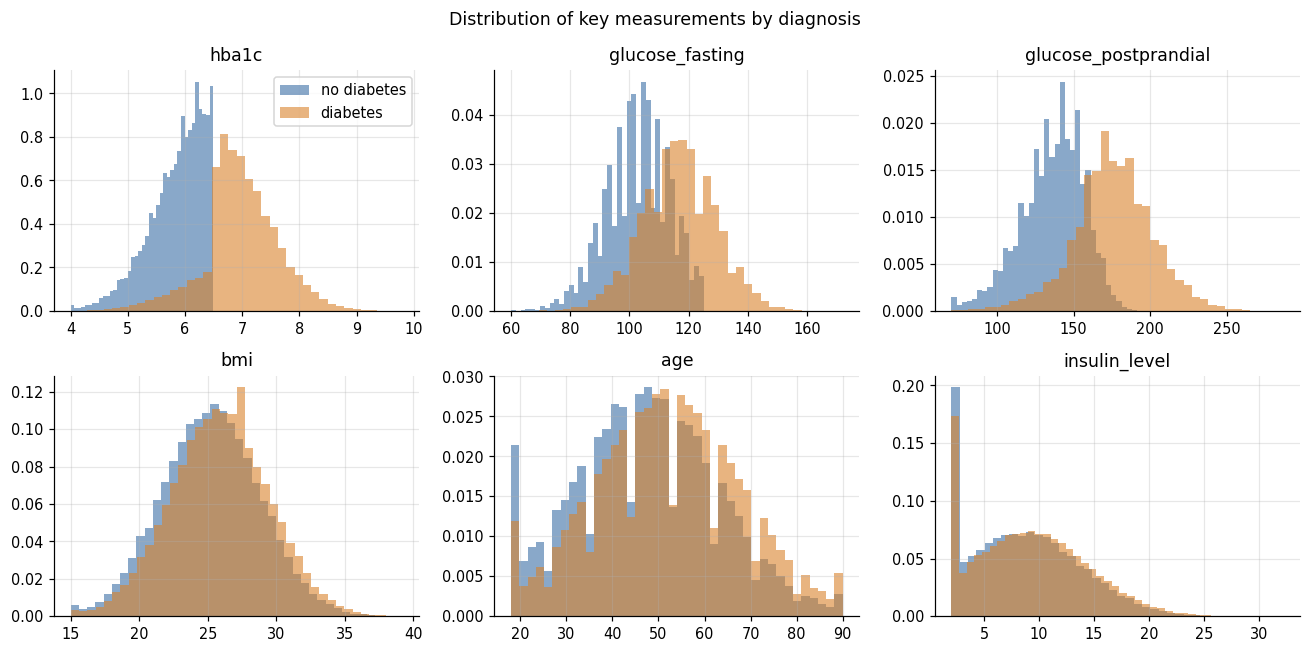

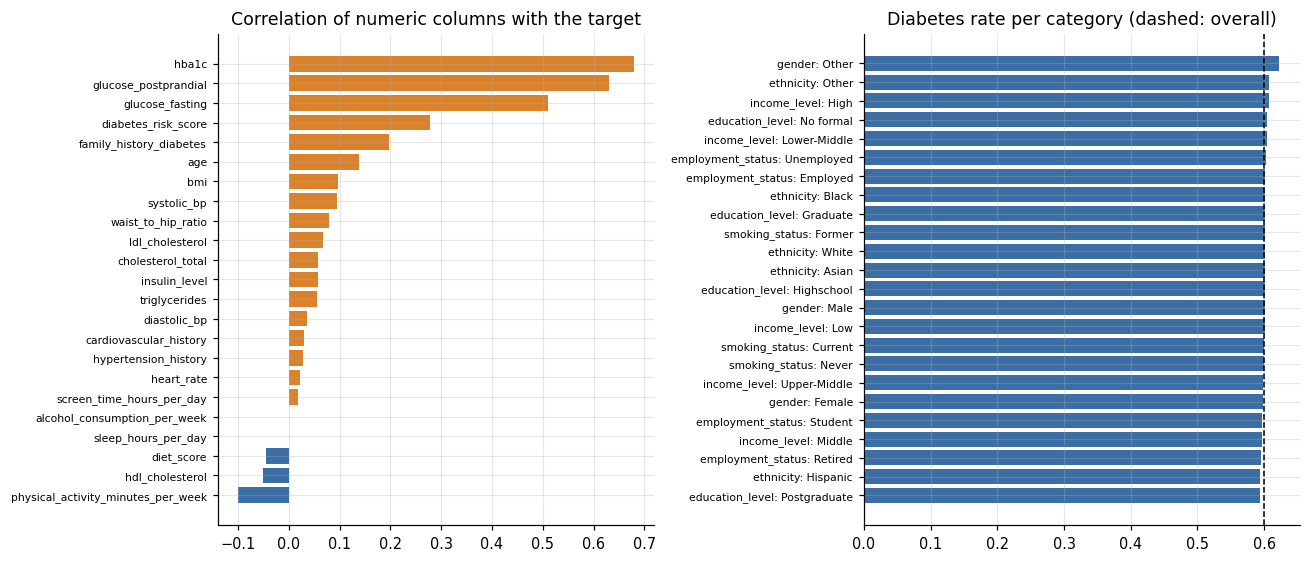

In [3]:
pos = df[TARGET].mean(); print(f'positive rate (diagnosed_diabetes = 1): {pos:.3f}  ({int(df[TARGET].sum()):,} of {len(df):,})')
fig, ax = plt.subplots(2, 3, figsize=(12, 6))
for a, c in zip(ax.ravel(), ['hba1c', 'glucose_fasting', 'glucose_postprandial', 'bmi', 'age', 'insulin_level']):
    a.hist(df.loc[df[TARGET] == 0, c], bins=40, alpha=.6, density=True, label='no diabetes', color=PAL)
    a.hist(df.loc[df[TARGET] == 1, c], bins=40, alpha=.6, density=True, label='diabetes', color=PAL2); a.set_title(c)
ax[0, 0].legend(); plt.suptitle('Distribution of key measurements by diagnosis'); plt.tight_layout(); savefig('eda_distributions'); plt.show()

num_cols = [c for c in df.columns if c not in cat_cols + [TARGET]]
corr_t = df[num_cols].corrwith(df[TARGET]).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
ax[0].barh(corr_t.index, corr_t.values, color=[PAL2 if v > 0 else PAL for v in corr_t.values]); ax[0].set_title('Correlation of numeric columns with the target'); ax[0].tick_params(axis='y', labelsize=7)
rates = []
for c in ['gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status']:
    for k, v in df.groupby(c)[TARGET].mean().items(): rates.append((f'{c}: {k}', v))
rates = pd.Series(dict(rates)).sort_values()
ax[1].barh(rates.index, rates.values, color=PAL); ax[1].axvline(pos, color='k', ls='--', lw=1); ax[1].set_title('Diabetes rate per category (dashed: overall)'); ax[1].tick_params(axis='y', labelsize=7)
plt.tight_layout(); savefig('eda_correlation_categories'); plt.show()

### Leakage: `diabetes_stage` and `diabetes_risk_score`

diagnosed_diabetes,0,1
diabetes_stage,,
Gestational,120,158
No Diabetes,7981,0
Pre-Diabetes,31845,0
Type 1,56,66
Type 2,0,59774


Type 2 -> always positive; No Diabetes / Pre-Diabetes -> always negative; only the 400 Gestational / Type 1 rows are mixed.
=> a model given `diabetes_stage` would "predict" the label almost perfectly without learning anything about risk. It is excluded.
`diabetes_risk_score` is almost a linear function of the other columns: R^2 = 0.993  -> it carries no extra information


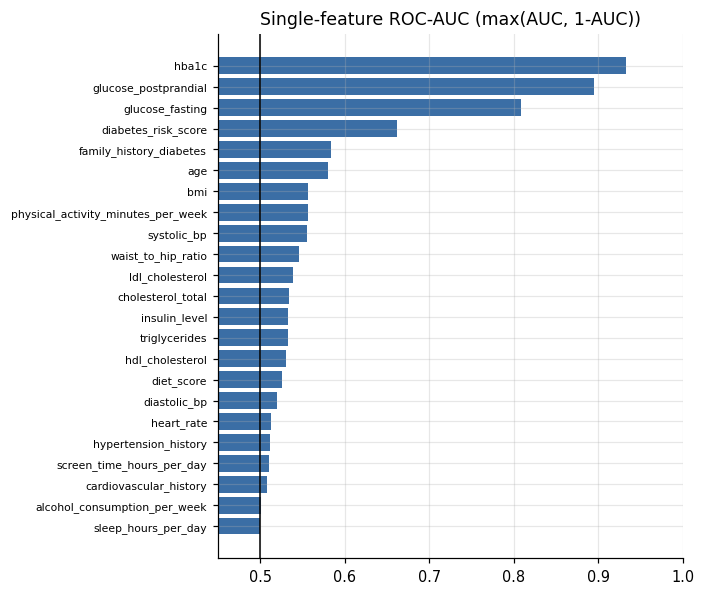

strongest single features: {'hba1c': 0.932, 'glucose_postprandial': 0.894, 'glucose_fasting': 0.808, 'diabetes_risk_score': 0.661}
clinical rule HbA1c >= 6.5 on all data: accuracy 0.911


In [4]:
ct = pd.crosstab(df.diabetes_stage, df[TARGET]); display(ct)
print('Type 2 -> always positive; No Diabetes / Pre-Diabetes -> always negative; only the 400 Gestational / Type 1 rows are mixed.')
print('=> a model given `diabetes_stage` would "predict" the label almost perfectly without learning anything about risk. It is excluded.')
from sklearn.linear_model import LinearRegression      # used only to describe the data (not a classifier of the task)
others = pd.get_dummies(df.drop(columns=[TARGET, 'diabetes_stage', 'diabetes_risk_score']), dtype=float)
r2 = LinearRegression().fit(others, df.diabetes_risk_score).score(others, df.diabetes_risk_score)
print(f'`diabetes_risk_score` is almost a linear function of the other columns: R^2 = {r2:.3f}  -> it carries no extra information')
auc1 = {c: roc_auc_score(df[TARGET], df[c]) for c in num_cols}
auc1 = pd.Series({c: max(a, 1 - a) for c, a in auc1.items()}).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5.5)); ax.barh(auc1.index, auc1.values, color=PAL); ax.axvline(.5, color='k', lw=1)
ax.set_xlim(.45, 1); ax.set_title('Single-feature ROC-AUC (max(AUC, 1-AUC))'); ax.tick_params(axis='y', labelsize=7); plt.tight_layout(); savefig('eda_single_feature_auc'); plt.show()
print('strongest single features:', auc1.sort_values(ascending=False).head(4).round(3).to_dict())
print('clinical rule HbA1c >= 6.5 on all data: accuracy %.3f' % ((df.hba1c >= 6.5).astype(int) == df[TARGET]).mean())
CLEAN = dict(rows=len(df), cols=df.shape[1], pos_rate=float(pos), r2_risk_score=float(r2))

## 3. Feature sets / scenarios and data split
`S1` and `S2` are the two main scenarios. The other feature sets are used only in the feature-set study (Section 7).

In [5]:
LEAK = ['diabetes_stage', 'diabetes_risk_score']; LABS = ['glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c']
BASECOLS = [c for c in df.columns if c not in [TARGET] + LEAK]
S2COLS = [c for c in BASECOLS if c not in LABS]
FEATSETS = {'S1': BASECOLS, 'S2': S2COLS, 'S2+hba1c': S2COLS + ['hba1c'], 'S2+glucose (2)': S2COLS + ['glucose_fasting', 'glucose_postprandial'],
            'S2+insulin': S2COLS + ['insulin_level'], 'lab tests only': LABS, 'S1+risk_score': BASECOLS + ['diabetes_risk_score'], 'S1+stage (LEAK)': BASECOLS + ['diabetes_stage']}
SCENS = ['S1', 'S2']; SNAME = {'S1': 'S1 (with lab tests)', 'S2': 'S2 (no lab tests)'}
print({k: len(v) for k, v in FEATSETS.items()})
y = df[TARGET].values.astype(np.float32)
idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
print('train / val / test rows:', len(tr), len(va), len(te), '| positive rate: %.3f / %.3f / %.3f' % (y[tr].mean(), y[va].mean(), y[te].mean()))

{'S1': 28, 'S2': 24, 'S2+hba1c': 25, 'S2+glucose (2)': 26, 'S2+insulin': 25, 'lab tests only': 4, 'S1+risk_score': 29, 'S1+stage (LEAK)': 29}
train / val / test rows: 70000 15000 15000 | positive rate: 0.600 / 0.600 / 0.600


## 4. Preprocessing engine
Every option is fitted on the **training rows only**.

| option | values |
|---|---|
| `enc` (categoricals) | `onehot` (all), `ordinal_mix` (education / income as ordered integers, the rest one-hot), `label_all` (integer codes for every categorical - a naive choice) |
| `scaler` | `standard`, `minmax`, `robust`, `quantile` (-> normal), `power` (Yeo-Johnson), `none` |
| `clip` | winsorise numeric columns at the 1st / 99th train percentile |
| `fe` | engineered features: pulse pressure, cholesterol / HDL ratios, non-HDL, TG / HDL, glucose delta, HOMA-IR, age x BMI, log of skewed columns (only if the raw columns exist in the scenario) |
| `pca` | PCA keeping 95 % of the variance |
| `corr` | drop one column of every pair with |r| > 0.9 |

In [6]:
ORD = {'education_level': ['No formal', 'Highschool', 'Graduate', 'Postgraduate'], 'income_level': ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High']}
NOM = ['gender', 'ethnicity', 'employment_status', 'smoking_status', 'diabetes_stage']
LEV = {c: sorted(df[c].unique()) for c in NOM}
SCALERS = dict(standard=StandardScaler, minmax=MinMaxScaler, robust=RobustScaler, power=PowerTransformer,
               quantile=lambda: QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=SEED))

def add_fe(d):
    d = d.copy(); has = lambda *c: all(x in d for x in c)
    if has('systolic_bp', 'diastolic_bp'): d['pulse_pressure'] = d.systolic_bp - d.diastolic_bp
    if has('cholesterol_total', 'hdl_cholesterol'): d['chol_hdl_ratio'] = d.cholesterol_total / d.hdl_cholesterol; d['non_hdl'] = d.cholesterol_total - d.hdl_cholesterol
    if has('triglycerides', 'hdl_cholesterol'): d['tg_hdl_ratio'] = d.triglycerides / d.hdl_cholesterol
    if has('glucose_fasting', 'glucose_postprandial'): d['glucose_delta'] = d.glucose_postprandial - d.glucose_fasting
    if has('glucose_fasting', 'insulin_level'): d['homa_ir'] = d.glucose_fasting * d.insulin_level / 405
    if has('age', 'bmi'): d['age_bmi'] = d.age * d.bmi / 100
    for c in ('triglycerides', 'insulin_level', 'alcohol_consumption_per_week'):
        if c in d: d['log_' + c] = np.log1p(d[c])
    return d

class Pre:
    def __init__(self, cols, enc='onehot', scaler='standard', clip=None, fe=False, pca=None, corr=None):
        self.cols, self.enc, self.scaler, self.clip, self.fe, self.pca, self.corr = cols, enc, scaler, clip, fe, pca, corr
    def _enc(self, d):
        d = add_fe(d[self.cols]) if self.fe else d[self.cols].copy()
        parts = []
        for c in list(d.columns):
            if c in ORD:
                if self.enc == 'onehot': parts.append(pd.get_dummies(pd.Categorical(d[c], categories=ORD[c]), prefix=c, prefix_sep='=', dtype=float).set_index(d.index)); d = d.drop(columns=c)
                else: d[c] = pd.Categorical(d[c], categories=ORD[c]).codes.astype(float)
            elif c in NOM:
                if self.enc == 'label_all': d[c] = pd.Categorical(d[c], categories=LEV[c]).codes.astype(float)
                else: parts.append(pd.get_dummies(pd.Categorical(d[c], categories=LEV[c]), prefix=c, prefix_sep='=', dtype=float).set_index(d.index)); d = d.drop(columns=c)
        return pd.concat([d] + parts, axis=1)
    def fit(self, dtr):
        e = self._enc(dtr); self.num = [c for c in e.columns if '=' not in c]; self.hot = [c for c in e.columns if '=' in c]
        if self.clip: self.lo, self.hi = e[self.num].quantile(self.clip[0]), e[self.num].quantile(self.clip[1]); e[self.num] = e[self.num].clip(self.lo, self.hi, axis=1)
        if self.corr:
            cm = e[self.num].corr().abs(); drop = set()
            for i, a in enumerate(self.num):
                for b in self.num[:i]:
                    if b not in drop and cm.loc[a, b] > self.corr: drop.add(a); break
            self.num = [c for c in self.num if c not in drop]
        self.sc = SCALERS[self.scaler]().fit(e[self.num]) if self.scaler != 'none' else None
        self.names = self.num + self.hot
        if self.pca: self.pc = PCA(self.pca, svd_solver='full', random_state=SEED).fit(self._raw(e))
        return self
    def _raw(self, e): return np.hstack([self.sc.transform(e[self.num]) if self.sc else e[self.num].values, e[self.hot].values]).astype(np.float32)
    def transform(self, d):
        e = self._enc(d)
        if self.clip: e[list(self.lo.index)] = e[list(self.lo.index)].clip(self.lo, self.hi, axis=1)
        X = self._raw(e)
        return (self.pc.transform(X).astype(np.float32) if self.pca else X)

DEFP = dict(enc='onehot', scaler='standard', clip=None, fe=False, pca=None, corr=None)
_DC = {}
def get_data(fs, P):
    key = (fs, json.dumps(P, sort_keys=True))
    if key not in _DC:
        pre = Pre(FEATSETS[fs], **P).fit(df.iloc[tr]); g = lambda a: torch.tensor(a, dtype=torch.float32, device=dev)
        _DC[key] = dict(pre=pre, Xtr=g(pre.transform(df.iloc[tr])), Xva=g(pre.transform(df.iloc[va])), Xte=g(pre.transform(df.iloc[te])),
                        ytr=g(y[tr]), yva=g(y[va]), yte=g(y[te]), dim=None)
        _DC[key]['dim'] = _DC[key]['Xtr'].shape[1]
    return _DC[key]
for fs in ('S1', 'S2'):
    d_ = get_data(fs, DEFP); print(fs, 'input dimension after default preprocessing:', d_['dim'])

S1 input dimension after default preprocessing: 46
S2 input dimension after default preprocessing: 42


## 5. Training engine (MLP only)
* `Linear -> [BatchNorm] -> activation -> [Dropout]` blocks and a single output logit (sigmoid -> probability of diabetes); `hidden=()` is a linear model.
* losses: binary cross-entropy (optionally label-smoothed / class-weighted) or focal loss; optimisers Adam, AdamW, SGD+Nesterov, RMSprop; LR schedules cosine / one-cycle / step.
* the data lives on the GPU; early stopping on **validation AUC** (patience 8, at most 40 epochs); the best epoch is restored.
* every training run is checkpointed to disk (resume after a crash returns exactly the numbers of the run that produced it) and logged in `RUNS`.

In [7]:
ACT = dict(relu=nn.ReLU, leaky_relu=lambda: nn.LeakyReLU(0.1), gelu=nn.GELU, elu=nn.ELU, silu=nn.SiLU, tanh=nn.Tanh, sigmoid=nn.Sigmoid)
def make_mlp(d_in, hidden, act='relu', dropout=0., bn=False):
    layers, d = [], d_in
    for h in hidden:
        layers.append(nn.Linear(d, h))
        if bn: layers.append(nn.BatchNorm1d(h))
        layers.append(ACT[act]())
        if dropout > 0: layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, 1)); return nn.Sequential(*layers)

DEF = dict(hidden=(128, 64), act='relu', dropout=0., bn=False, opt='adam', lr=1e-3, wd=0., bs=512, epochs=40, patience=8, sched='cosine',
           loss='bce', gamma=2.0, class_weight=False, label_smooth=0., in_noise=0.)

def _fit(fs, P, seed=0, keep=False, frac=1.0, **cfg):
    c = {**DEF, **cfg}; D = get_data(fs, P); torch.manual_seed(seed); np.random.seed(seed)
    Xtr, ytr, Xva, yva = D['Xtr'], D['ytr'], D['Xva'], D['yva']
    if frac < 1:
        sel = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(seed))[:int(len(Xtr) * frac)].to(dev); Xtr, ytr = Xtr[sel], ytr[sel]
    N = len(Xtr); model = make_mlp(D['dim'], c['hidden'], c['act'], c['dropout'], c['bn']).to(dev); Pm = model.parameters()
    opt = dict(adam=lambda: torch.optim.Adam(Pm, c['lr'], weight_decay=c['wd']), adamw=lambda: torch.optim.AdamW(Pm, c['lr'], weight_decay=c['wd']),
               sgd=lambda: torch.optim.SGD(Pm, c['lr'], momentum=0.9, nesterov=True, weight_decay=c['wd']),
               rmsprop=lambda: torch.optim.RMSprop(Pm, c['lr'], weight_decay=c['wd']))[c['opt']]()
    steps = (N + c['bs'] - 1) // c['bs']
    sch = dict(none=None, cosine=lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, c['epochs']),
               onecycle=lambda: torch.optim.lr_scheduler.OneCycleLR(opt, c['lr'], total_steps=c['epochs'] * steps, cycle_momentum=False),
               step=lambda: torch.optim.lr_scheduler.StepLR(opt, max(1, c['epochs'] // 3), 0.3))[c['sched']]
    sch = sch() if sch else None
    posw = (1 - ytr.mean()) / ytr.mean() if c['class_weight'] else None
    yv_np = yva.cpu().numpy(); sub = slice(0, min(10000, N)); best, bad, state, t0 = dict(auc=-1), 0, None, time.time()
    hist = dict(tr_loss=[], va_loss=[], tr_acc=[], va_acc=[], va_auc=[])
    for ep in range(c['epochs']):
        model.train(); idx_ = torch.randperm(N, device=dev); tl = 0.
        for i in range(steps):
            b = idx_[i * c['bs']:(i + 1) * c['bs']]
            if len(b) < 2: continue
            xb, yb = Xtr[b], ytr[b]
            if c['in_noise']: xb = xb + c['in_noise'] * torch.randn_like(xb)
            z = model(xb).squeeze(1); ys = yb * (1 - c['label_smooth']) + 0.5 * c['label_smooth']
            bce = F.binary_cross_entropy_with_logits(z, ys, pos_weight=posw, reduction='none')
            if c['loss'] == 'focal': bce = ((1 - torch.exp(-F.binary_cross_entropy_with_logits(z, ys, reduction='none'))) ** c['gamma']) * bce
            loss = bce.mean(); opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tl += loss.item()
            if c['sched'] == 'onecycle': sch.step()
        if sch is not None and c['sched'] != 'onecycle': sch.step()
        model.eval()
        with torch.no_grad():
            zv = model(Xva).squeeze(1); vl = F.binary_cross_entropy_with_logits(zv, yva).item(); pv = torch.sigmoid(zv).cpu().numpy()
            tra = ((model(Xtr[sub]).squeeze(1) > 0).float() == ytr[sub]).float().mean().item()
        auc = roc_auc_score(yv_np, pv); acc = float(((pv > .5) == (yv_np > .5)).mean())
        for k, v in zip(hist, (tl / steps, vl, tra, acc, auc)): hist[k].append(v)
        if auc > best['auc'] + 1e-5:
            tp_ = ((pv > .5) & (yv_np > .5)).sum(); f1 = 2 * tp_ / max(2 * tp_ + ((pv > .5) & (yv_np < .5)).sum() + ((pv <= .5) & (yv_np > .5)).sum(), 1)
            best, bad = dict(auc=auc, acc=acc, f1=float(f1), ll=vl, ep=ep, tr_acc=tra), 0
            if keep: state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= c['patience']: break
    out = dict(va_auc=best['auc'], va_acc=best['acc'], va_f1=best['f1'], va_ll=best['ll'], best_ep=best['ep'] + 1, tr_acc=best['tr_acc'],
               time=time.time() - t0, hist=hist, n_params=sum(p.numel() for p in model.parameters()))
    if keep:
        model.load_state_dict(state); model.eval()
        with torch.no_grad(): out['va_prob'] = torch.sigmoid(model(Xva).squeeze(1)).cpu().numpy(); out['te_prob'] = torch.sigmoid(model(D['Xte']).squeeze(1)).cpu().numpy()
        out['model'] = model
    return out

CKPT = os.path.join(tempfile.gettempdir(), 'diabetes_mlp_ckpt'); os.makedirs(CKPT, exist_ok=True)
def fit(fs, P, seed=0, keep=False, frac=1.0, **cfg):
    if keep: return _fit(fs, P, seed, keep, frac, **cfg)
    key = hashlib.md5(json.dumps([fs, P, seed, frac, {**DEF, **cfg}], sort_keys=True, default=str).encode()).hexdigest(); fn = os.path.join(CKPT, key + '.pkl')
    if os.path.exists(fn):
        with open(fn, 'rb') as f: return pickle.load(f)
    out = _fit(fs, P, seed, keep, frac, **cfg)
    with open(fn, 'wb') as f: pickle.dump(out, f)
    return out

RUNS = []
def run(fs, exp, label, seeds=(0, 1), P=None, **cfg):
    P = {**DEFP, **(P or {})}; outs = [fit(fs, P, s, **cfg) for s in seeds]; m = lambda k: float(np.mean([o[k] for o in outs]))
    rec = dict(fs=fs, exp=exp, label=label, P=P, cfg={**DEF, **cfg}, n_seeds=len(seeds), va_auc=m('va_auc'), va_auc_sd=float(np.std([o['va_auc'] for o in outs])),
               va_acc=m('va_acc'), va_f1=m('va_f1'), va_ll=m('va_ll'), tr_acc=m('tr_acc'), best_ep=m('best_ep'), time=m('time'), n_params=outs[0]['n_params'])
    RUNS.append(rec); rec['_hist'] = outs[0]['hist']; return rec

STATE = {s: dict(P=dict(DEFP), cfg=dict(DEF)) for s in SCENS}        # current best configuration per scenario (updated greedily)

def barpanel(ax, items, title, ref=None):
    ys = np.arange(len(items))[::-1]; vals = [i[1] for i in items]
    ax.barh(ys, vals, xerr=[i[2] for i in items], color=PAL, alpha=.9, capsize=2); ax.set_yticks(ys); ax.set_yticklabels([i[0] for i in items], fontsize=7.5)
    lo, hi = min(vals), max(vals); pad = max((hi - lo) * .6, .004); ax.set_xlim(lo - pad, hi + pad * .8)
    for yy, v in zip(ys, vals): ax.text(v + pad * .03, yy, f'{v:.4f}', va='center', fontsize=7)
    if ref is not None: ax.axvline(ref, color='#c0392b', ls='--', lw=1)
    ax.set_title(title, fontsize=9.5); ax.set_xlabel('validation ROC-AUC')
def panels(item_lists, title, fname, refs=None, h=None):
    n = max(len(v) for v in item_lists.values()); fig, axes = plt.subplots(1, len(item_lists), figsize=(13, h or (0.27 * n + 1.4)))
    for ax, (s, items) in zip(np.atleast_1d(axes), item_lists.items()): barpanel(ax, items, SNAME[s], (refs or {}).get(s))
    plt.suptitle(title, y=1.0); plt.tight_layout(); savefig(fname); plt.show()
def table(exp_prefix, fs):
    d = pd.DataFrame([{k: v for k, v in r.items() if k not in ('cfg', '_hist', 'P')} for r in RUNS if r['exp'].startswith(exp_prefix) and r['fs'] == fs])
    return d.sort_values('va_auc', ascending=False)[['label', 'va_auc', 'va_auc_sd', 'va_acc', 'va_f1', 'tr_acc', 'best_ep', 'n_params']].round(4)

## 6. Experiment 1 - baseline MLP
`input -> 128 -> 64 -> 1`, ReLU, Adam 1e-3, batch 512, standard scaling, one-hot categoricals, no regularisation; three seeds.

            S1 (with lab tests)  S2 (no lab tests)
val_auc                  0.9421             0.6624
val_acc                  0.9077             0.6332
val_f1                   0.9178             0.7291
train_acc                0.9106             0.6346
best_epoch               6.0000             2.6667
params               14337.0000         13825.0000


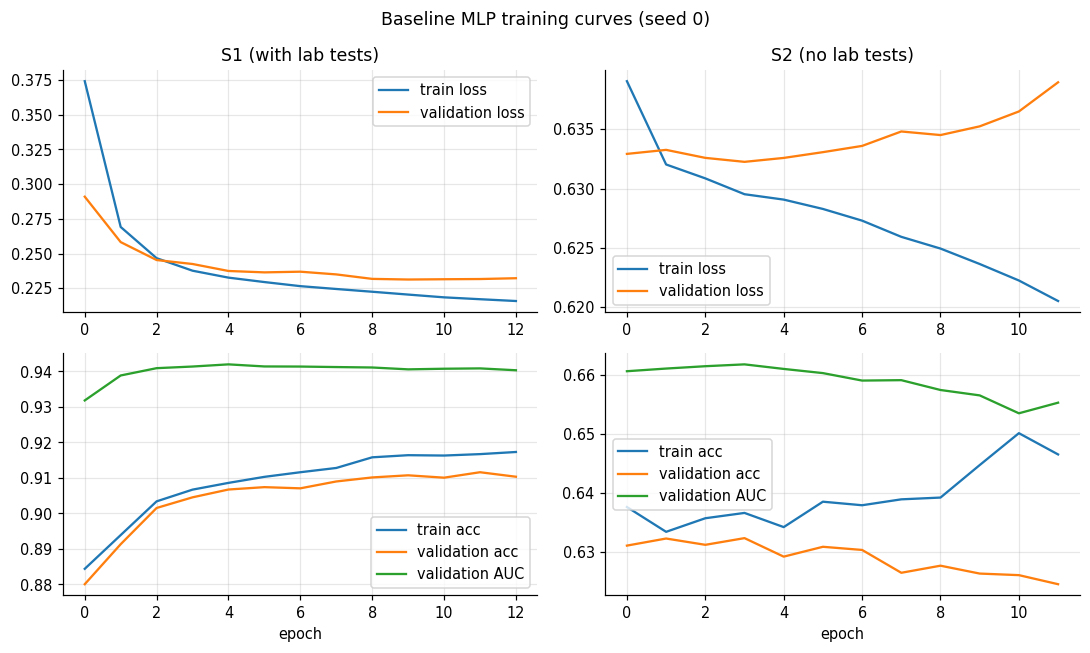

In [8]:
base = {s: run(s, 'baseline', 'baseline MLP 128-64', seeds=(0, 1, 2), P={}, **DEF) for s in SCENS}
print(pd.DataFrame({SNAME[s]: dict(val_auc=r['va_auc'], val_acc=r['va_acc'], val_f1=r['va_f1'], train_acc=r['tr_acc'], best_epoch=r['best_ep'], params=r['n_params']) for s, r in base.items()}).round(4))
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for j, s in enumerate(SCENS):
    h = base[s]['_hist']; ax[0, j].plot(h['tr_loss'], label='train loss'); ax[0, j].plot(h['va_loss'], label='validation loss'); ax[0, j].set_title(SNAME[s]); ax[0, j].legend()
    ax[1, j].plot(h['tr_acc'], label='train acc'); ax[1, j].plot(h['va_acc'], label='validation acc'); ax[1, j].plot(h['va_auc'], label='validation AUC'); ax[1, j].set_xlabel('epoch'); ax[1, j].legend()
plt.suptitle('Baseline MLP training curves (seed 0)'); plt.tight_layout(); savefig('baseline_curves'); plt.show()

**Observations.** The baseline MLP (128-64) reaches **AUC 0.942 / accuracy 90.8 %** in S1 and **AUC 0.662 / accuracy 63.3 %** in S2 (3 seeds, seed std <= 0.0005 AUC). Unlike the image problem, there is **no over-fitting**: training accuracy (91.1 % / 63.5 %) is about equal to validation accuracy, and early stopping picks very early epochs (6 and ~3). On this small, well-conditioned tabular problem the network learns what there is to learn within a few epochs. The two scenarios are worlds apart: the lab tests move AUC from 0.66 to 0.94.

## 7. Experiment 2 - which information does the model get? (feature sets and leakage)
Same baseline MLP, different sets of input columns: what the lab tests add, whether `diabetes_risk_score` helps, and what happens if the leaking `diabetes_stage` is (wrongly) included.

,label,n_inputs,va_auc,va_acc,va_f1
0,S1,28,0.9421,0.9079,0.9180
1,S2,24,0.6621,0.6330,0.7307
2,S2+hba1c,25,0.9413,0.9056,0.9154
3,S2+glucose (2),26,0.9127,0.8389,0.8606
4,S2+insulin,25,0.6626,0.6329,0.7292
5,lab tests only,4,0.9366,0.9149,0.9245
6,S1+risk_score,29,0.9429,0.9083,0.9184
7,S1+stage (LEAK),29,1.0000,0.9991,0.9992


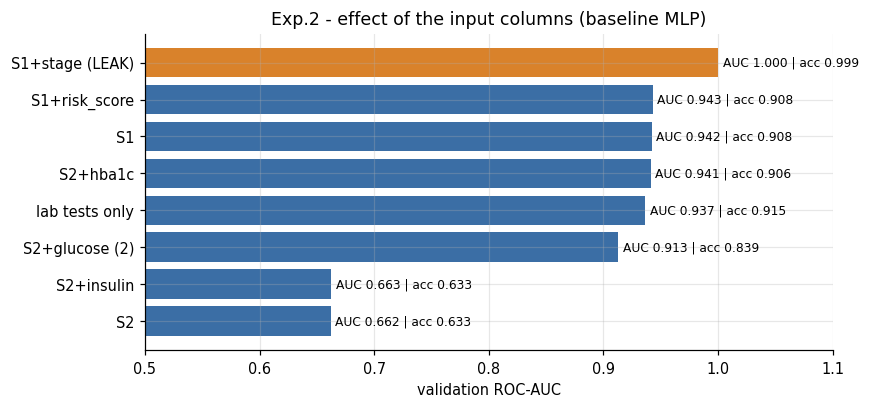

In [9]:
fsets = [run(f, 'featset', f, seeds=(0, 1), P={}, **DEF) for f in FEATSETS]
d_ = pd.DataFrame([{k: r[k] for k in ('label', 'va_auc', 'va_acc', 'va_f1')} for r in fsets]).round(4); d_.insert(1, 'n_inputs', [len(FEATSETS[f]) for f in FEATSETS]); display(d_)
fig, ax = plt.subplots(figsize=(8, 3.8)); items = sorted(fsets, key=lambda r: r['va_auc']); ax.barh([r['label'] for r in items], [r['va_auc'] for r in items], color=[PAL2 if 'LEAK' in r['label'] else PAL for r in items])
for i, r in enumerate(items): ax.text(r['va_auc'] + .004, i, f"AUC {r['va_auc']:.3f} | acc {r['va_acc']:.3f}", va='center', fontsize=8)
ax.set_xlim(.5, 1.1); ax.set_xlabel('validation ROC-AUC'); ax.set_title('Exp.2 - effect of the input columns (baseline MLP)'); plt.tight_layout(); savefig('exp2_featuresets'); plt.show()

**Observations.**
* **The lab tests carry almost all the signal.** Adding HbA1c alone to the no-lab columns lifts AUC from 0.662 to **0.941** (full S1: 0.942); the four lab values *alone* give 0.937 - lifestyle, demographics and vitals add almost nothing once HbA1c is known. Both glucose values without HbA1c reach only 0.913 (accuracy 83.9 %); insulin adds nothing (0.663).
* **`diabetes_risk_score` does not help** (0.943 vs 0.942, inside seed noise), consistent with R^2 = 0.993 against the other columns: it contains no new information.
* **`diabetes_stage` gives AUC 1.000 and accuracy 99.9 %** - a perfect score that measures leakage, not risk prediction (the stage is defined from the diagnosis). Any near-perfect result reported on this dataset should be checked for this.

## 8. Experiment 3 - preprocessing
One factor at a time around the current best configuration (two seeds). A value is **adopted** only if it beats the base validation AUC by more than
max(0.002, seed std); the adopted values are then combined and re-checked.

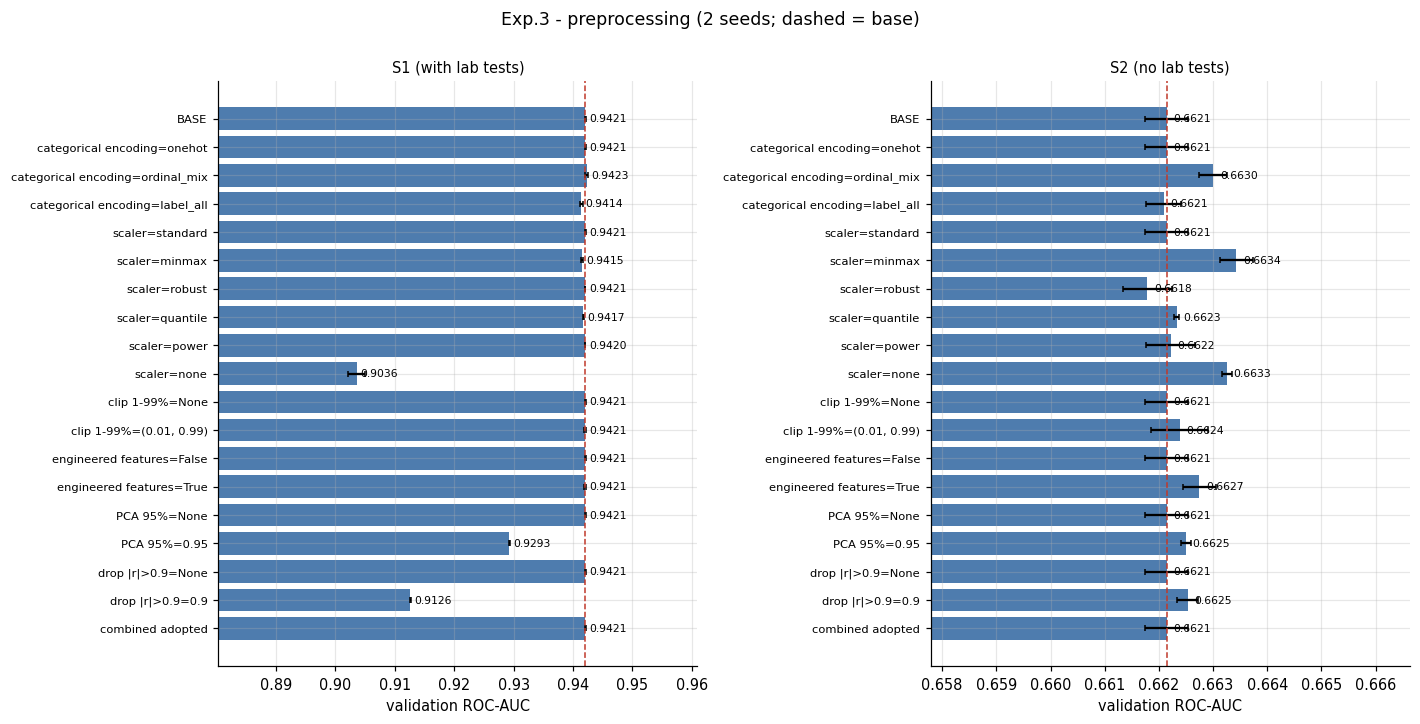

S1 (with lab tests): adopted {} | base AUC 0.9421 -> combined 0.9421 | current preprocessing: default
S2 (no lab tests): adopted {} | base AUC 0.6621 -> combined 0.6621 | current preprocessing: default


In [10]:
def merge_adopt(adopt, ch):
    for k, v in ch.items():
        if k == 'P': adopt.setdefault('P', {}).update(v)
        else: adopt[k] = v
def sweep(fs, exp, base_cfg, base_P, factors, seeds=(0, 1)):
    def go(label, ch): return run(fs, exp, label, seeds=seeds, P={**base_P, **ch.get('P', {})}, **{**base_cfg, **{k: v for k, v in ch.items() if k != 'P'}})
    def same(ch): return all((base_cfg.get(k) == v) if k != 'P' else all(base_P.get(kk) == vv for kk, vv in v.items()) for k, v in ch.items())
    base_rec = go('base', {}); res, adopt = {}, {}; thr = max(0.002, base_rec['va_auc_sd'])
    for fname, opts in factors.items():
        recs = [(f'{fname}={lab}', base_rec if same(ch) else go(f'{fname}={lab}', ch), ch) for lab, ch in opts]; res[fname] = recs
        b = max(recs, key=lambda t: t[1]['va_auc'])
        if b[1]['va_auc'] > base_rec['va_auc'] + thr: merge_adopt(adopt, b[2])
    comb_rec = go('combined adopted', adopt) if adopt else base_rec
    if comb_rec['va_auc'] >= base_rec['va_auc']: cfg, P = {**base_cfg, **{k: v for k, v in adopt.items() if k != 'P'}}, {**base_P, **adopt.get('P', {})}
    else: cfg, P = base_cfg, base_P
    return dict(cfg=cfg, P=P, base=base_rec, comb=comb_rec, res=res, adopt=adopt)
def factor_items(sw):
    items = [('BASE', sw['base']['va_auc'], sw['base']['va_auc_sd'])] + [(lab, r['va_auc'], r['va_auc_sd']) for fl in sw['res'].values() for lab, r, _ in fl] + [('combined adopted', sw['comb']['va_auc'], sw['comb']['va_auc_sd'])]
    seen, out = set(), []
    for it in items:
        if it[0] not in seen: seen.add(it[0]); out.append(it)
    return out

prep_factors = {'categorical encoding': [(e, {'P': {'enc': e}}) for e in ('onehot', 'ordinal_mix', 'label_all')],
                'scaler': [(s, {'P': {'scaler': s}}) for s in ('standard', 'minmax', 'robust', 'quantile', 'power', 'none')],
                'clip 1-99%': [(c, {'P': {'clip': c}}) for c in (None, (0.01, 0.99))],
                'engineered features': [(f, {'P': {'fe': f}}) for f in (False, True)],
                'PCA 95%': [(p, {'P': {'pca': p}}) for p in (None, 0.95)],
                'drop |r|>0.9': [(c, {'P': {'corr': c}}) for c in (None, 0.9)]}
SW_PREP = {s: sweep(s, 'prep', STATE[s]['cfg'], STATE[s]['P'], prep_factors) for s in SCENS}
panels({s: factor_items(SW_PREP[s]) for s in SCENS}, 'Exp.3 - preprocessing (2 seeds; dashed = base)', 'exp3_preprocessing', refs={s: SW_PREP[s]['base']['va_auc'] for s in SCENS})
for s in SCENS:
    STATE[s]['cfg'], STATE[s]['P'] = SW_PREP[s]['cfg'], SW_PREP[s]['P']
    print(f"{SNAME[s]}: adopted {SW_PREP[s]['adopt']} | base AUC {SW_PREP[s]['base']['va_auc']:.4f} -> combined {SW_PREP[s]['comb']['va_auc']:.4f} | current preprocessing: { {k: v for k, v in STATE[s]['P'].items() if v != DEFP[k]} or 'default'}")

**Observations.**
* **S1:** scaling only matters when it is missing - with raw inputs AUC falls to 0.904 (accuracy 82.9 %) because the columns have very different ranges. All real scalers (standard, robust, power, quantile) are equal within 0.001; min-max is slightly lower (0.9415). Categorical encoding (one-hot 0.9421 vs ordinal 0.9423), winsorising and engineered features (pulse pressure, cholesterol ratios, HOMA-IR, ...) change nothing: an MLP can build such combinations itself, and the signal is dominated by HbA1c.
* **Two options hurt:** PCA keeping 95 % of the variance (0.929) discards low-variance directions that are still predictive, and **dropping one column of every pair with |r| > 0.9 (0.913) removes HbA1c** (it correlates 0.93 with post-meal glucose) - a correlation filter is not safe when the redundant-looking feature is the best predictor.
* **S2:** all variants lie in 0.662-0.663 (differences <= 0.0013 are noise; un-scaled inputs even work, but converge much more slowly: ~24 epochs vs ~2.5). Nothing met the adoption rule in either scenario, so the default (one-hot + standardisation) is kept.

## 9. Experiment 4 - architecture
`hidden = ()` is a linear model (logistic regression); it is run only as a **reference point** and is *not eligible* to be selected, because a model without a hidden layer is not an MLP.
Then a 4 x 4 grid (1-4 hidden layers x 16 / 64 / 256 / 512 units) plus other shapes; two seeds, current best preprocessing.

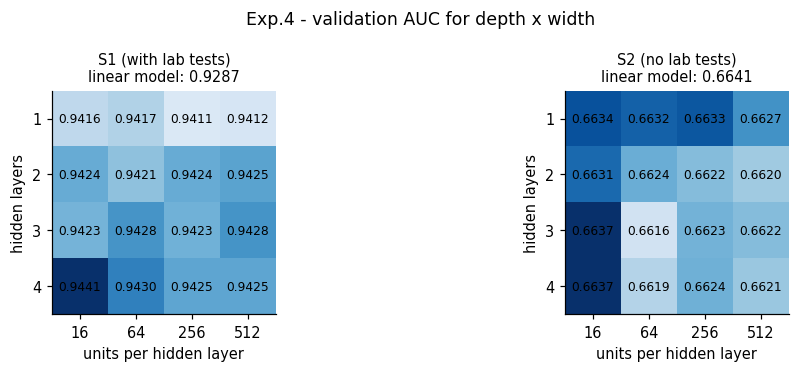

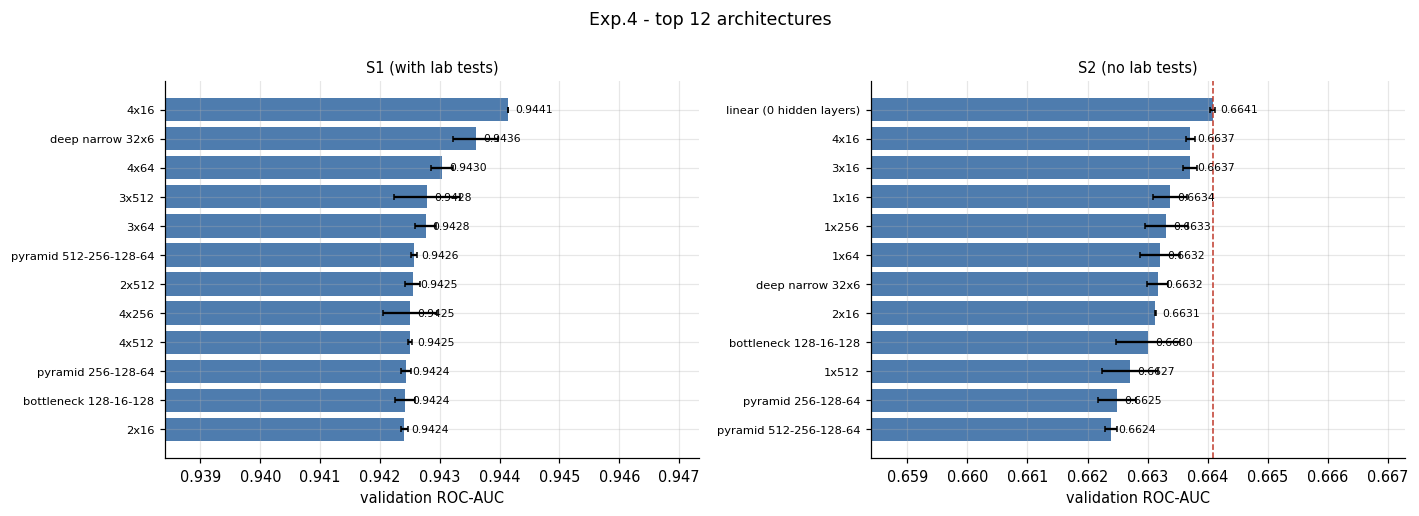

,label,va_auc,va_auc_sd,va_acc,va_f1,tr_acc,best_ep,n_params,setting
13,4x16,0.9441,0.0000,0.9181,0.9271,0.9177,32.5,1585,S1 (with lab tests)
21,deep narrow 32x6,0.9436,0.0004,0.9157,0.9250,0.9194,27.5,6817,S1 (with lab tests)
14,4x64,0.9430,0.0002,0.9131,0.9228,0.9204,18.0,15553,S1 (with lab tests)
12,3x512,0.9428,0.0005,0.9087,0.9191,0.9180,6.0,549889,S1 (with lab tests)
10,3x64,0.9428,0.0002,0.9136,0.9233,0.9196,18.0,11393,S1 (with lab tests)
20,pyramid 512-256-128-64,0.9426,0.0000,0.9083,0.9188,0.9164,6.0,196609,S1 (with lab tests)
8,2x512,0.9425,0.0001,0.9083,0.9186,0.9158,4.5,287233,S1 (with lab tests)
15,4x256,0.9425,0.0004,0.9071,0.9177,0.9151,5.5,209665,S1 (with lab tests)


S1 (with lab tests) best architecture (>= 1 hidden layer): (16, 16, 16, 16) | linear reference AUC 0.9287


,label,va_auc,va_auc_sd,va_acc,va_f1,tr_acc,best_ep,n_params,setting
0,linear (0 hidden layers),0.6641,0.0000,0.6334,0.7312,0.6299,12.5,43,S2 (no lab tests)
13,4x16,0.6637,0.0001,0.6347,0.7293,0.6324,5.0,1521,S2 (no lab tests)
9,3x16,0.6637,0.0001,0.6346,0.7296,0.6326,7.5,1249,S2 (no lab tests)
1,1x16,0.6634,0.0003,0.6333,0.7279,0.6324,5.0,705,S2 (no lab tests)
3,1x256,0.6633,0.0004,0.6337,0.7304,0.6315,2.5,11265,S2 (no lab tests)
2,1x64,0.6632,0.0003,0.6330,0.7274,0.6337,4.5,2817,S2 (no lab tests)
21,deep narrow 32x6,0.6632,0.0002,0.6341,0.7316,0.6376,5.0,6689,S2 (no lab tests)
5,2x16,0.6631,0.0000,0.6335,0.7283,0.6317,5.0,977,S2 (no lab tests)


S2 (no lab tests) best architecture (>= 1 hidden layer): (16, 16, 16, 16) | linear reference AUC 0.6641


In [11]:
ARCH, WIDTHS = {}, (16, 64, 256, 512)
best_mlp = lambda s: max([r for k, r in ARCH[s].items() if k != 'linear'], key=lambda r: r['va_auc'])   # a real MLP has >= 1 hidden layer
shapes = {'wide 2048': (2048,), 'pyramid 256-128-64': (256, 128, 64), 'bottleneck 128-16-128': (128, 16, 128), 'pyramid 512-256-128-64': (512, 256, 128, 64), 'deep narrow 32x6': (32,) * 6}
for s in SCENS:
    cfg0, P0 = STATE[s]['cfg'], STATE[s]['P']; R = {}
    R['linear'] = run(s, 'arch', 'linear (0 hidden layers)', P=P0, **{**cfg0, 'hidden': ()})
    for d in (1, 2, 3, 4):
        for w in WIDTHS: R[(d, w)] = run(s, 'arch', f'{d}x{w}', P=P0, **{**cfg0, 'hidden': (w,) * d})
    for k, h in shapes.items(): R[k] = run(s, 'arch', k, P=P0, **{**cfg0, 'hidden': h})
    ARCH[s] = R
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, s in zip(ax, SCENS):
    g = np.array([[ARCH[s][(d, w)]['va_auc'] for w in WIDTHS] for d in (1, 2, 3, 4)]); im = a.imshow(g, cmap='Blues', vmin=g.min() - .0005, vmax=g.max())
    a.set_xticks(range(4)); a.set_xticklabels(WIDTHS); a.set_yticks(range(4)); a.set_yticklabels((1, 2, 3, 4)); a.set_xlabel('units per hidden layer'); a.set_ylabel('hidden layers'); a.grid(False)
    for i in range(4):
        for j in range(4): a.text(j, i, f'{g[i, j]:.4f}', ha='center', va='center', fontsize=8)
    a.set_title(f"{SNAME[s]}\nlinear model: {ARCH[s]['linear']['va_auc']:.4f}", fontsize=9.5)
plt.suptitle('Exp.4 - validation AUC for depth x width'); plt.tight_layout(); savefig('exp4_arch_grid'); plt.show()
panels({s: [(r['label'], r['va_auc'], r['va_auc_sd']) for r in sorted(ARCH[s].values(), key=lambda r: -r['va_auc'])[:12]] for s in SCENS}, 'Exp.4 - top 12 architectures', 'exp4_arch_top', refs={s: ARCH[s]['linear']['va_auc'] for s in SCENS})
for s in SCENS:
    display(table('arch', s).head(8).assign(setting=SNAME[s]))
    STATE[s]['cfg'] = {**STATE[s]['cfg'], 'hidden': best_mlp(s)['cfg']['hidden']}; print(SNAME[s], 'best architecture (>= 1 hidden layer):', STATE[s]['cfg']['hidden'], '| linear reference AUC %.4f' % ARCH[s]['linear']['va_auc'])

**Observations.**
* The grid is **flat**: S1 spans 0.9411-0.9441, S2 0.6616-0.6637. The best architecture in both scenarios is the small **4 x 16** network (S1 0.9441, S2 0.6637; only 1,585 parameters); more width does not help (S1 4 x 512: 0.9425, 2048 wide: 0.9401). More capacity cannot add information that is not in the columns.
* **S1:** the linear reference (no hidden layer) reaches only AUC 0.9287 / accuracy 85.4 % vs 0.9441 / 91.8 % for 4 x 16, so **hidden layers are necessary**: the diagnosis follows a threshold-like rule on HbA1c (about 6.5), which a linear model cannot represent but a few ReLU units can.
* **S2:** the linear model is as good as any MLP (0.6641 vs 0.6637): there is no non-linear structure to exploit. It is kept only as a reference; the selected model is the best network with at least one hidden layer.

## 10. Experiment 5 - activation functions

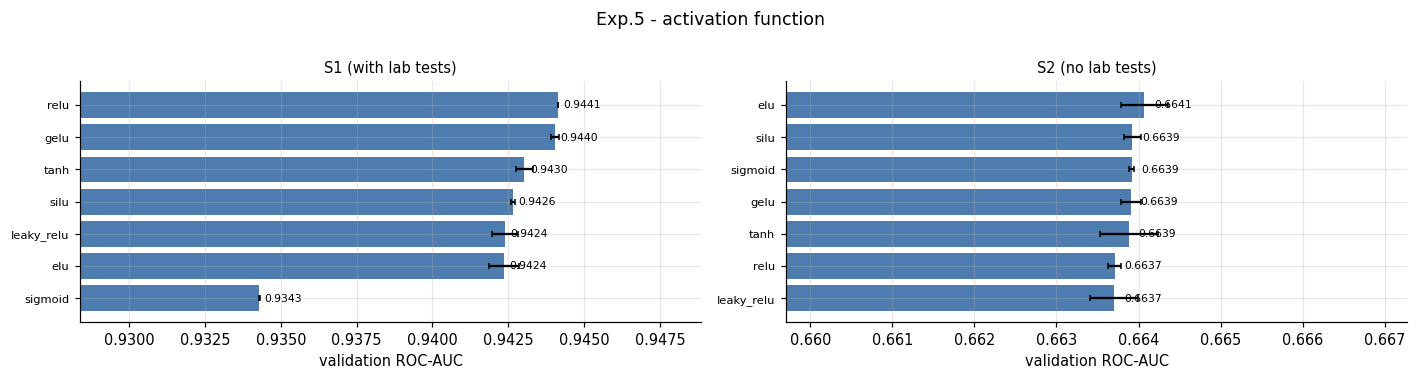

,label,va_auc,va_auc_sd,va_acc,va_f1,tr_acc,best_ep,n_params,setting
0,relu,0.9441,0.0000,0.9181,0.9271,0.9177,32.5,1585,S1 (with lab tests)
2,gelu,0.9440,0.0001,0.9157,0.9249,0.9168,29.5,1585,S1 (with lab tests)
5,tanh,0.9430,0.0003,0.9092,0.9184,0.9085,20.0,1585,S1 (with lab tests)
4,silu,0.9426,0.0001,0.9093,0.9187,0.9089,23.5,1585,S1 (with lab tests)
1,leaky_relu,0.9424,0.0004,0.9101,0.9195,0.9104,18.0,1585,S1 (with lab tests)
3,elu,0.9424,0.0005,0.9097,0.9192,0.9088,15.0,1585,S1 (with lab tests)
6,sigmoid,0.9343,0.0000,0.9042,0.9150,0.9044,9.5,1585,S1 (with lab tests)


S1 (with lab tests) best activation: relu


,label,va_auc,va_auc_sd,va_acc,va_f1,tr_acc,best_ep,n_params,setting
3,elu,0.6641,0.0003,0.6336,0.7253,0.6308,7.5,1521,S2 (no lab tests)
4,silu,0.6639,0.0001,0.6337,0.7285,0.6322,10.5,1521,S2 (no lab tests)
6,sigmoid,0.6639,0.0000,0.6330,0.7193,0.6303,21.5,1521,S2 (no lab tests)
2,gelu,0.6639,0.0001,0.6350,0.7290,0.6318,8.5,1521,S2 (no lab tests)
5,tanh,0.6639,0.0004,0.6335,0.7263,0.6310,7.5,1521,S2 (no lab tests)
0,relu,0.6637,0.0001,0.6347,0.7293,0.6324,5.0,1521,S2 (no lab tests)
1,leaky_relu,0.6637,0.0003,0.6348,0.7263,0.6305,3.5,1521,S2 (no lab tests)


S2 (no lab tests) best activation: elu


In [12]:
ACTR = {s: [run(s, 'act', a, P=STATE[s]['P'], **{**STATE[s]['cfg'], 'act': a}) for a in ACT] for s in SCENS}
panels({s: [(r['label'], r['va_auc'], r['va_auc_sd']) for r in sorted(ACTR[s], key=lambda r: -r['va_auc'])] for s in SCENS}, 'Exp.5 - activation function', 'exp5_activation', h=3.4)
for s in SCENS:
    display(table('act', s).assign(setting=SNAME[s])); STATE[s]['cfg'] = {**STATE[s]['cfg'], 'act': max(ACTR[s], key=lambda r: r['va_auc'])['label']}; print(SNAME[s], 'best activation:', STATE[s]['cfg']['act'])

**Observations.** **S1:** ReLU 0.9441, GELU 0.9440, tanh 0.9430, SiLU 0.9426, Leaky-ReLU and ELU 0.9424, sigmoid 0.9343 (about 1 point lower). ReLU-type units suit a step-like decision rule; sigmoid is clearly the weakest. **S2:** all seven activations lie within 0.6637-0.6641 (ELU 'wins' by 0.0002, which is noise).

## 11. Experiment 6 - regularisation
Dropout, batch-norm, weight decay (AdamW), label smoothing and input noise, around the current best model (two seeds, adoption rule as before).

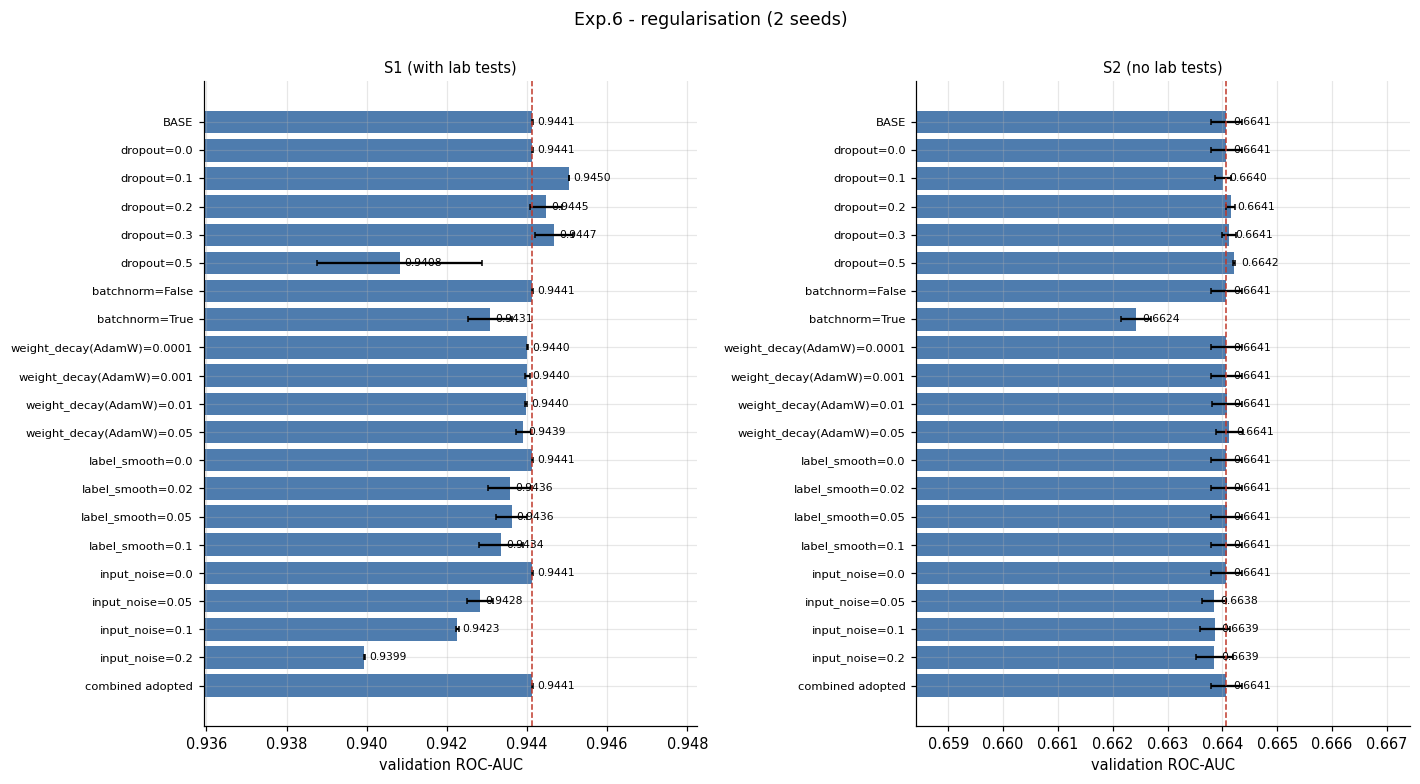

S1 (with lab tests): adopted {} | base AUC 0.9441 -> combined 0.9441
S2 (no lab tests): adopted {} | base AUC 0.6641 -> combined 0.6641


In [13]:
reg_factors = {'dropout': [(d, {'dropout': d}) for d in (0., .1, .2, .3, .5)], 'batchnorm': [(b, {'bn': b}) for b in (False, True)],
               'weight_decay(AdamW)': [(w, {'opt': 'adamw', 'wd': w}) for w in (1e-4, 1e-3, 1e-2, 5e-2)],
               'label_smooth': [(v, {'label_smooth': v}) for v in (0., .02, .05, .1)], 'input_noise': [(v, {'in_noise': v}) for v in (0., .05, .1, .2)]}
SW_REG = {s: sweep(s, 'reg', STATE[s]['cfg'], STATE[s]['P'], reg_factors) for s in SCENS}
panels({s: factor_items(SW_REG[s]) for s in SCENS}, 'Exp.6 - regularisation (2 seeds)', 'exp6_regularisation', refs={s: SW_REG[s]['base']['va_auc'] for s in SCENS})
for s in SCENS:
    STATE[s]['cfg'], STATE[s]['P'] = SW_REG[s]['cfg'], SW_REG[s]['P']
    print(f"{SNAME[s]}: adopted {SW_REG[s]['adopt']} | base AUC {SW_REG[s]['base']['va_auc']:.4f} -> combined {SW_REG[s]['comb']['va_auc']:.4f}")

**Observations.** **No regulariser helps** and nothing met the adoption rule in either scenario. S1: dropout 0.1-0.3 gives 0.9445-0.9450 vs 0.9441 (a tie), dropout 0.5 hurts (0.9408), batch-norm 0.9431, weight decay has no effect (0.9439-0.9440; the model has only 1.6k parameters), label smoothing 0.9434-0.9436, and input noise hurts more the more is added (0.9428 -> 0.9399). S2: every setting lies in 0.6638-0.6642 except batch-norm (0.6624). The reason is simple: **these networks do not over-fit** (training accuracy is equal to validation accuracy), so there is nothing for regularisation to repair - the opposite of the face-image task.

## 12. Experiment 7 - optimiser, learning rate, batch size, LR schedule
Optimisers other than AdamW are run with **weight decay = 0** (a coupled L2 penalty copied from the previous stage would confound the comparison).

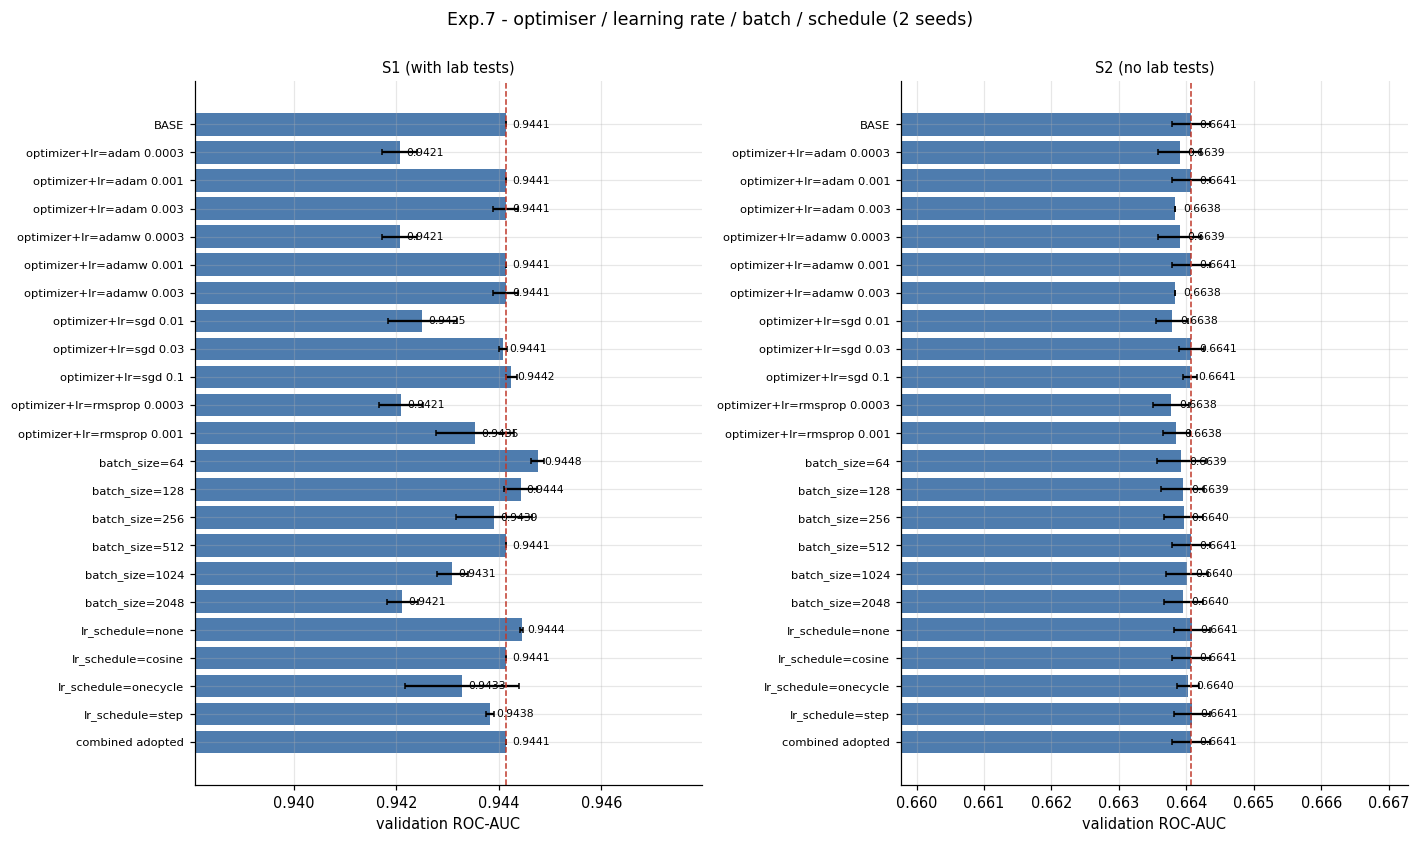

S1 (with lab tests): adopted {} | base AUC 0.9441 -> combined 0.9441
S2 (no lab tests): adopted {} | base AUC 0.6641 -> combined 0.6641


In [14]:
def optopt(o, l): return {'opt': o, 'lr': l} if o == 'adamw' else {'opt': o, 'lr': l, 'wd': 0.}
opt_factors = {'optimizer+lr': [(f'{o} {l:g}', optopt(o, l)) for o, ls in (('adam', (3e-4, 1e-3, 3e-3)), ('adamw', (3e-4, 1e-3, 3e-3)), ('sgd', (.01, .03, .1)), ('rmsprop', (3e-4, 1e-3))) for l in ls],
               'batch_size': [(b, {'bs': b}) for b in (64, 128, 256, 512, 1024, 2048)], 'lr_schedule': [(v, {'sched': v}) for v in ('none', 'cosine', 'onecycle', 'step')]}
SW_OPT = {s: sweep(s, 'opt', STATE[s]['cfg'], STATE[s]['P'], opt_factors) for s in SCENS}
panels({s: factor_items(SW_OPT[s]) for s in SCENS}, 'Exp.7 - optimiser / learning rate / batch / schedule (2 seeds)', 'exp7_optimisation', refs={s: SW_OPT[s]['base']['va_auc'] for s in SCENS})
for s in SCENS:
    STATE[s]['cfg'], STATE[s]['P'] = SW_OPT[s]['cfg'], SW_OPT[s]['P']
    print(f"{SNAME[s]}: adopted {SW_OPT[s]['adopt']} | base AUC {SW_OPT[s]['base']['va_auc']:.4f} -> combined {SW_OPT[s]['comb']['va_auc']:.4f}")

**Observations.** (Optimisers other than AdamW were run with weight decay 0.)
* **S1:** a learning rate of 3e-4 is too small for 40 epochs (Adam / AdamW / RMSprop: 0.9421); 1e-3 and 3e-3 are equal (0.9441); SGD with Nesterov momentum needs a large rate (0.01: 0.9425, 0.03: 0.9441, 0.1: 0.9442). **Smaller batches are slightly better**: 64 -> 0.9448, 128 -> 0.9444, 256 -> 0.9439, 512 -> 0.9441, 1024 -> 0.9431, 2048 -> 0.9421 (large batches give too few updates on this small problem). LR schedules are tied (none 0.9444, cosine 0.9441, step 0.9438, one-cycle 0.9433).
* **S2:** all settings lie within 0.6638-0.6641, i.e. the optimiser is irrelevant.
* No change reached the adoption threshold (0.002 AUC), so the base configuration is kept.

## 13. Experiment 8 - loss function and class balance
The positive class is 60 % (mild imbalance). Options: plain BCE, class-weighted BCE (`pos_weight`), focal loss (gamma 1 and 2).

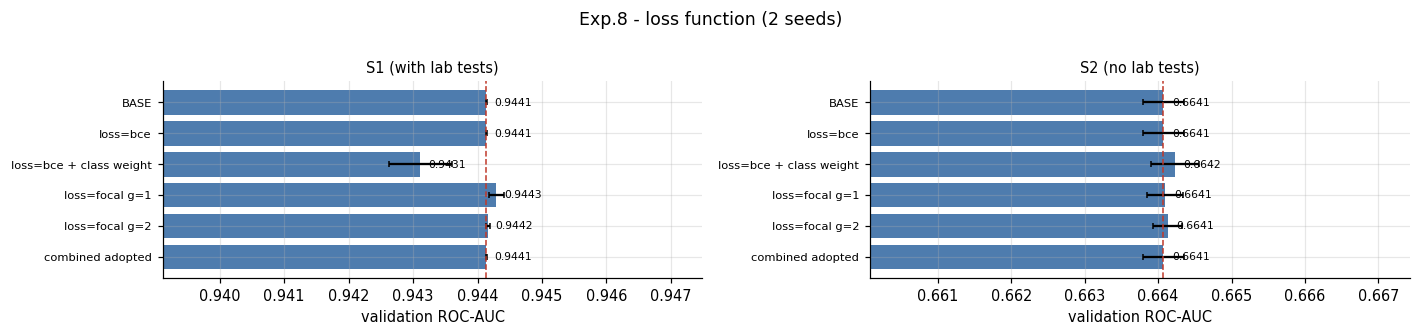

S1 (with lab tests): adopted {}
   current best (greedy) configuration: {'hidden': (16, 16, 16, 16)} | preprocessing: {}
S2 (no lab tests): adopted {}
   current best (greedy) configuration: {'hidden': (16, 16, 16, 16), 'act': 'elu'} | preprocessing: {}


In [15]:
loss_factors = {'loss': [('bce', {'loss': 'bce', 'class_weight': False}), ('bce + class weight', {'loss': 'bce', 'class_weight': True}),
                         ('focal g=1', {'loss': 'focal', 'gamma': 1.0, 'class_weight': False}), ('focal g=2', {'loss': 'focal', 'gamma': 2.0, 'class_weight': False})]}
SW_LOSS = {s: sweep(s, 'loss', STATE[s]['cfg'], STATE[s]['P'], loss_factors) for s in SCENS}
panels({s: factor_items(SW_LOSS[s]) for s in SCENS}, 'Exp.8 - loss function (2 seeds)', 'exp8_loss', refs={s: SW_LOSS[s]['base']['va_auc'] for s in SCENS}, h=3)
for s in SCENS:
    STATE[s]['cfg'], STATE[s]['P'] = SW_LOSS[s]['cfg'], SW_LOSS[s]['P']; print(f"{SNAME[s]}: adopted {SW_LOSS[s]['adopt']}")
    print('   current best (greedy) configuration:', {k: v for k, v in STATE[s]['cfg'].items() if DEF.get(k) != v}, '| preprocessing:', {k: v for k, v in STATE[s]['P'].items() if v != DEFP[k]})

**Observations.** Plain binary cross-entropy is as good as focal loss (S1 0.9441 vs 0.9442-0.9443; S2 identical, 0.6641). **Class weighting lowers accuracy** (S1 91.3 %, S2 60.6 %) and slightly lowers AUC, because it down-weights the majority (positive) class and moves the decision point away from the true 60/40 prior. With a mild imbalance there is no problem for it to solve; the decision threshold (Section 17d) is the better lever. Not adopted.

## 14. Experiment 9 - joint random search
30 random configurations per scenario over architecture, activation, dropout, batch-norm, optimiser, lr, weight decay, batch size, label smoothing and the preprocessing
(scaler, engineered features). Trial 0 is the greedy best configuration found so far. One seed per trial.

S1 trial 00 AUC 0.9441 acc 0.9185 (16, 16, 16, 16) relu do=0.0 bn=False adam lr=0.0010 bs=512 scaler=standard fe=False
S1 trial 01 AUC 0.9395 acc 0.9079 (256, 128) gelu do=0.2 bn=True adamw lr=0.0010 bs=256 scaler=power fe=False
S1 trial 02 AUC 0.9433 acc 0.9160 (64, 64, 64, 64) leaky_relu do=0.2 bn=False adam lr=0.0003 bs=256 scaler=power fe=False
S1 trial 03 AUC 0.9403 acc 0.9051 (128, 64) relu do=0.0 bn=True adamw lr=0.0005 bs=256 scaler=quantile fe=False
S1 trial 04 AUC 0.9402 acc 0.9025 (256,) relu do=0.1 bn=False adam lr=0.0004 bs=256 scaler=standard fe=True
S1 trial 05 AUC 0.9393 acc 0.8997 (64,) gelu do=0.0 bn=False adam lr=0.0007 bs=512 scaler=power fe=True
S1 trial 06 AUC 0.9425 acc 0.9081 (128, 64) relu do=0.1 bn=True adamw lr=0.0006 bs=256 scaler=quantile fe=True
S1 trial 07 AUC 0.9410 acc 0.9069 (256, 128) leaky_relu do=0.1 bn=True adam lr=0.0019 bs=512 scaler=quantile fe=True
S1 trial 08 AUC 0.9405 acc 0.9081 (256,) leaky_relu do=0.2 bn=False adamw lr=0.0014 bs=1024 scale

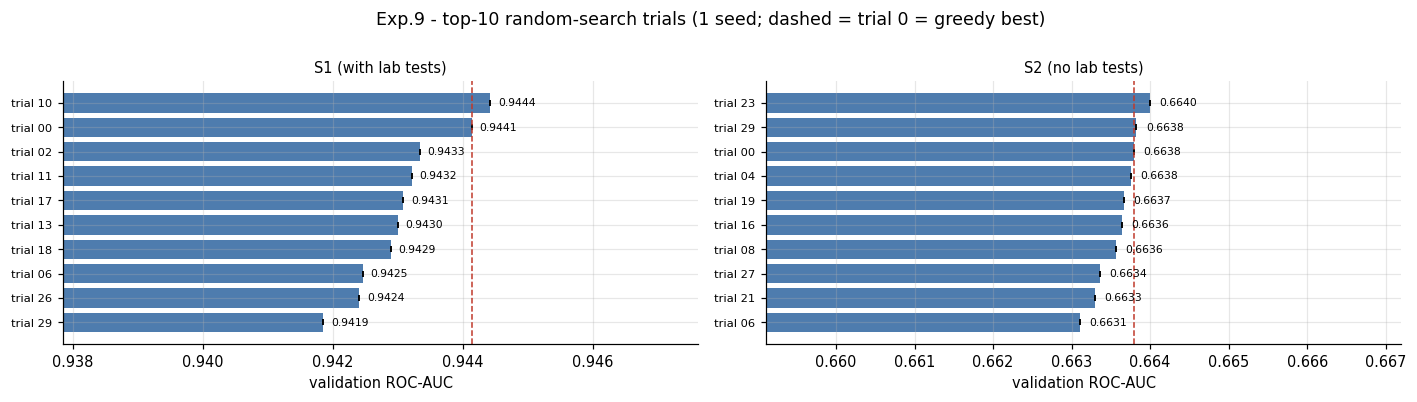

In [16]:
rs = np.random.RandomState(7)
SPACE = dict(hidden=[(64,), (128,), (256,), (128, 64), (256, 128), (256, 128, 64), (512, 256, 128), (128, 128, 128), (64, 64, 64, 64)], act=['relu', 'gelu', 'silu', 'leaky_relu'],
             dropout=[0., .1, .2, .3], bn=[False, True], opt=['adam', 'adamw'], bs=[256, 512, 1024], label_smooth=[0., .02, .05])
RSR = {s: [] for s in SCENS}
for s in SCENS:
    for i in range(30):
        if i == 0: cfg, P = dict(STATE[s]['cfg']), dict(STATE[s]['P'])
        else:
            cfg = {**DEF, **{k: v[rs.randint(len(v))] for k, v in SPACE.items()}}; cfg['lr'] = float(10 ** rs.uniform(np.log10(3e-4), np.log10(3e-3)))
            cfg['wd'] = float(10 ** rs.uniform(-5, -2)) if cfg['opt'] == 'adamw' else 0.; P = {**DEFP, 'scaler': ['standard', 'quantile', 'power'][rs.randint(3)], 'fe': bool(rs.randint(2))}
        r = run(s, 'random_search', f'trial {i:02d}', seeds=(0,), P=P, **cfg); RSR[s].append(r)
        print(f"{s} trial {i:02d} AUC {r['va_auc']:.4f} acc {r['va_acc']:.4f} {r['cfg']['hidden']} {r['cfg']['act']} do={r['cfg']['dropout']} bn={r['cfg']['bn']} {r['cfg']['opt']} lr={r['cfg']['lr']:.4f} bs={r['cfg']['bs']} scaler={P['scaler']} fe={P['fe']}")
panels({s: [(r['label'], r['va_auc'], 0) for r in sorted(RSR[s], key=lambda r: -r['va_auc'])[:10]] for s in SCENS}, 'Exp.9 - top-10 random-search trials (1 seed; dashed = trial 0 = greedy best)', 'exp9_random_search', refs={s: RSR[s][0]['va_auc'] for s in SCENS}, h=3.6)

**Observations.** The 30 random configurations span 0.9371-0.9444 in S1 (median 0.9411) and 0.6586-0.6640 in S2 (median 0.6628). The greedy configuration (trial 0: 0.9441 / 0.6638) is already within 0.0003 AUC of the best random trial, so a joint search finds nothing better. Re-training the five best configurations seen anywhere with three fresh seeds gives 0.9434-0.9447 (S1) and 0.6640-0.6641 (S2): they are **statistically tied**. We therefore did not pick the final model by a 0.0001 AUC difference, but, among finalists within 0.0005 AUC, by the lowest validation log-loss (best-calibrated probabilities). This tie-break was added after a first complete run in which an AUC-only choice had selected a focal-loss model with distorted probabilities (calibration error 0.072 instead of 0.012). Final models: S1 4 x 16 ReLU + dropout 0.2; S2 4 x 16 ELU + AdamW (weight decay 0.05).

## 15. Cross-check with scikit-learn's `MLPClassifier`
An independent MLP implementation (CPU) with the architecture and preprocessing chosen for each scenario so far.

In [17]:
from sklearn.neural_network import MLPClassifier
SK = []
for s in SCENS:
    D = get_data(s, STATE[s]['P']); t0 = time.time(); Xtr_, ytr_, Xva_, yva_ = [D[k].cpu().numpy() for k in ('Xtr', 'ytr', 'Xva', 'yva')]
    clf = MLPClassifier(hidden_layer_sizes=tuple(STATE[s]['cfg']['hidden']), alpha=1e-4, batch_size=512, early_stopping=True, n_iter_no_change=6, max_iter=60, random_state=0).fit(Xtr_, ytr_)
    p_ = clf.predict_proba(Xva_)[:, 1]; SK.append(dict(scenario=SNAME[s], hidden=str(STATE[s]['cfg']['hidden']), val_auc=roc_auc_score(yva_, p_), val_acc=accuracy_score(yva_, p_ > .5), epochs=clf.n_iter_, sec=time.time() - t0))
display(pd.DataFrame(SK).round(4))

,scenario,hidden,val_auc,val_acc,epochs,sec
0,S1 (with lab tests),"(16, 16, 16, 16)",0.9445,0.9156,36,2.2517
1,S2 (no lab tests),"(16, 16, 16, 16)",0.6593,0.6329,13,0.9464


## 16. Final models and test evaluation
For each scenario: (1) take the 5 best distinct configurations seen in *any* experiment (by validation AUC; mostly single-seed -> optimistic), (2) re-train each with 3 fresh seeds,
(3) keep the best mean AUC - finalists within 0.0005 AUC of the best count as tied and the one with the lowest validation log-loss (best-calibrated probabilities) is chosen
(this tie-break was added after a first complete run showed that an AUC-only choice had picked a focal-loss model with distorted probabilities), (4) train it with 5 new seeds and evaluate each seed **and the 5-MLP average-probability ensemble** once on the test set.
Decision thresholds are chosen on the validation set only.

In [18]:
FINAL = {}
for s in SCENS:
    cand = []
    for r in sorted([r for r in RUNS if r['fs'] == s and r['exp'] != 'featset'], key=lambda r: -r['va_auc']):
        key = json.dumps([r['P'], r['cfg']], sort_keys=True, default=str)
        if key not in [k for k, _ in cand]: cand.append((key, r))
        if len(cand) == 5: break
    rech = []
    for k, r in cand:
        rr = run(s, 'final_recheck', f"{r['exp']}/{r['label']}", seeds=(10, 11, 12), P=r['P'], **{**r['cfg'], 'hidden': tuple(r['cfg']['hidden'])}); rech.append(rr)
        print(f"{s} {r['exp']:>14s} / {r['label']:<22s} first AUC {r['va_auc']:.4f} -> re-check (3 fresh seeds) AUC {rr['va_auc']:.4f} +- {rr['va_auc_sd']:.4f} acc {rr['va_acc']:.4f}")
    top = max(r['va_auc'] for r in rech); tied = [r for r in rech if r['va_auc'] >= top - 0.0005]; best = min(tied, key=lambda r: r['va_ll'])   # AUC ties -> best-calibrated (lowest log-loss)
    print(f'{s}: {len(tied)} of {len(rech)} finalists are within 0.0005 AUC of the best; tie broken by validation log-loss ->', best['label'], '(log-loss %.4f)' % best['va_ll']); FINAL[s] =dict(P=best['P'], cfg={**best['cfg'], 'hidden': tuple(best['cfg']['hidden'])}, rec=best)
    print(f"-> {SNAME[s]} FINAL: preprocessing { {k: v for k, v in best['P'].items() if v != DEFP[k]} or 'default'}; config { {k: v for k, v in FINAL[s]['cfg'].items() if DEF.get(k) != v} }\n")

S1            reg / dropout=0.1            first AUC 0.9450 -> re-check (3 fresh seeds) AUC 0.9442 +- 0.0008 acc 0.9172
S1            opt / batch_size=64          first AUC 0.9448 -> re-check (3 fresh seeds) AUC 0.9447 +- 0.0003 acc 0.9174
S1            reg / dropout=0.3            first AUC 0.9447 -> re-check (3 fresh seeds) AUC 0.9439 +- 0.0001 acc 0.9184
S1            reg / dropout=0.2            first AUC 0.9445 -> re-check (3 fresh seeds) AUC 0.9445 +- 0.0004 acc 0.9183
S1            opt / lr_schedule=none       first AUC 0.9444 -> re-check (3 fresh seeds) AUC 0.9434 +- 0.0006 acc 0.9125
S1: 3 of 5 finalists are within 0.0005 AUC of the best; tie broken by validation log-loss -> reg/dropout=0.2 (log-loss 0.2170)
-> S1 (with lab tests) FINAL: preprocessing default; config {'hidden': (16, 16, 16, 16), 'dropout': 0.2}

S2           loss / loss=bce + class weight first AUC 0.6642 -> re-check (3 fresh seeds) AUC 0.6640 +- 0.0001 acc 0.6083
S2            reg / dropout=0.5            fir

In [19]:
def ece_score(yt, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1); e = 0.
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(yt[m].mean() - p[m].mean())
    return float(e)
def clf_metrics(yt, p, thr=.5):
    yh = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yt, yh, labels=[0, 1]).ravel()
    return dict(thr=float(thr), acc=float((tp + tn) / len(yt)), auc=float(roc_auc_score(yt, p)), ap=float(average_precision_score(yt, p)), f1=float(2 * tp / max(2 * tp + fp + fn, 1)),
                prec=float(tp / max(tp + fp, 1)), sens=float(tp / max(tp + fn, 1)), spec=float(tn / max(tn + fp, 1)), brier=float(brier_score_loss(yt, p)),
                logloss=float(log_loss(yt, np.clip(p, 1e-6, 1 - 1e-6))), ece=ece_score(yt, p), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
yva_np, yte_np = y[va], y[te]; FM = {}
for s in SCENS:
    fin = [fit(s, FINAL[s]['P'], seed=sd, keep=True, **FINAL[s]['cfg']) for sd in (100, 101, 102, 103, 104)]; FM[s] = fin
    ens_va = np.mean([f['va_prob'] for f in fin], 0); ens_te = np.mean([f['te_prob'] for f in fin], 0)
    ths = np.linspace(.05, .95, 181); f1s = [clf_metrics(yva_np, ens_va, t)['f1'] for t in ths]; thr_f1 = float(ths[int(np.argmax(f1s))])
    sens_ok = [t for t in ths if clf_metrics(yva_np, ens_va, t)['sens'] >= .90]; thr_sens = float(max(sens_ok)) if sens_ok else float(ths[0])
    single = [clf_metrics(yte_np, f['te_prob']) for f in fin]
    FINAL[s].update(single=single, ens_va=ens_va, ens_te=ens_te, thr_f1=thr_f1, thr_sens=thr_sens, m_ens=clf_metrics(yte_np, ens_te, .5), m_f1=clf_metrics(yte_np, ens_te, thr_f1), m_sens=clf_metrics(yte_np, ens_te, thr_sens))
    sg = lambda k: (np.mean([m[k] for m in single]), np.std([m[k] for m in single]))
    print(f"=== {SNAME[s]}: {sum(f['n_params'] for f in fin) // 5:,} parameters per model")
    print('  single MLPs (5 seeds)  TEST acc %.4f +- %.4f | AUC %.4f +- %.4f | F1 %.4f' % (*sg('acc'), *sg('auc'), sg('f1')[0]))
    for nm, m in (('ensemble @0.5', FINAL[s]['m_ens']), (f'ensemble @{thr_f1:.2f} (max val F1)', FINAL[s]['m_f1']), (f'ensemble @{thr_sens:.2f} (val sens>=0.90)', FINAL[s]['m_sens'])):
        print(f"  {nm:<36s} acc {m['acc']:.4f} AUC {m['auc']:.4f} F1 {m['f1']:.4f} prec {m['prec']:.3f} sens {m['sens']:.3f} spec {m['spec']:.3f} | Brier {m['brier']:.4f} ECE {m['ece']:.4f}")
    print('  validation (single models) AUC %.4f acc %.4f' % (np.mean([f['va_auc'] for f in fin]), np.mean([f['va_acc'] for f in fin])))
def boot_ci(yt, p, n=1000):
    r = np.random.RandomState(0); a, u = [], []
    for _ in range(n):
        i = r.randint(0, len(yt), len(yt)); a.append(float(((p[i] >= .5) == (yt[i] > .5)).mean())); u.append(float(roc_auc_score(yt[i], p[i])))
    return [float(v) for v in np.percentile(a, [2.5, 97.5])], [float(v) for v in np.percentile(u, [2.5, 97.5])]
for s in SCENS:
    FINAL[s]['ci_acc'], FINAL[s]['ci_auc'] = boot_ci(yte_np, FINAL[s]['ens_te'])
    print(f"{SNAME[s]}: ensemble test accuracy {FINAL[s]['m_ens']['acc']:.4f} (95% bootstrap CI {FINAL[s]['ci_acc'][0]:.4f}-{FINAL[s]['ci_acc'][1]:.4f}) | AUC {FINAL[s]['m_ens']['auc']:.4f} (95% CI {FINAL[s]['ci_auc'][0]:.4f}-{FINAL[s]['ci_auc'][1]:.4f})")
print('\nreferences on the test set: majority class acc %.4f | clinical rule HbA1c>=6.5: acc %.4f, sens %.3f, spec %.3f' % (max(yte_np.mean(), 1 - yte_np.mean()),
      *[clf_metrics(yte_np, (df.hba1c.values[te] >= 6.5).astype(float))[k] for k in ('acc', 'sens', 'spec')]))
RULE = clf_metrics(yte_np, (df.hba1c.values[te] >= 6.5).astype(float)); MAJ = float(max(yte_np.mean(), 1 - yte_np.mean()))

=== S1 (with lab tests): 1,585 parameters per model
  single MLPs (5 seeds)  TEST acc 0.9188 +- 0.0008 | AUC 0.9436 +- 0.0006 | F1 0.9277
  ensemble @0.5                        acc 0.9203 AUC 0.9442 F1 0.9289 prec 0.998 sens 0.869 spec 0.998 | Brier 0.0663 ECE 0.0068
  ensemble @0.59 (max val F1)          acc 0.9203 AUC 0.9442 F1 0.9289 prec 0.999 sens 0.868 spec 0.999 | Brier 0.0663 ECE 0.0068
  ensemble @0.20 (val sens>=0.90)      acc 0.8752 AUC 0.9442 F1 0.8965 prec 0.892 sens 0.901 spec 0.836 | Brier 0.0663 ECE 0.0068
  validation (single models) AUC 0.9448 acc 0.9179


=== S2 (no lab tests): 1,521 parameters per model
  single MLPs (5 seeds)  TEST acc 0.6273 +- 0.0014 | AUC 0.6518 +- 0.0004 | F1 0.7228
  ensemble @0.5                        acc 0.6279 AUC 0.6522 F1 0.7232 prec 0.653 sens 0.810 spec 0.354 | Brier 0.2235 ECE 0.0120
  ensemble @0.37 (max val F1)          acc 0.6089 AUC 0.6522 F1 0.7518 prec 0.607 sens 0.987 spec 0.041 | Brier 0.2235 ECE 0.0120
  ensemble @0.45 (val sens>=0.90)      acc 0.6235 AUC 0.6522 F1 0.7407 prec 0.631 sens 0.897 spec 0.214 | Brier 0.2235 ECE 0.0120
  validation (single models) AUC 0.6635 acc 0.6332


S1 (with lab tests): ensemble test accuracy 0.9203 (95% bootstrap CI 0.9161-0.9245) | AUC 0.9442 (95% CI 0.9406-0.9480)


S2 (no lab tests): ensemble test accuracy 0.6279 (95% bootstrap CI 0.6201-0.6354) | AUC 0.6522 (95% CI 0.6433-0.6602)

references on the test set: majority class acc 0.5999 | clinical rule HbA1c>=6.5: acc 0.9104, sens 0.851, spec 1.000


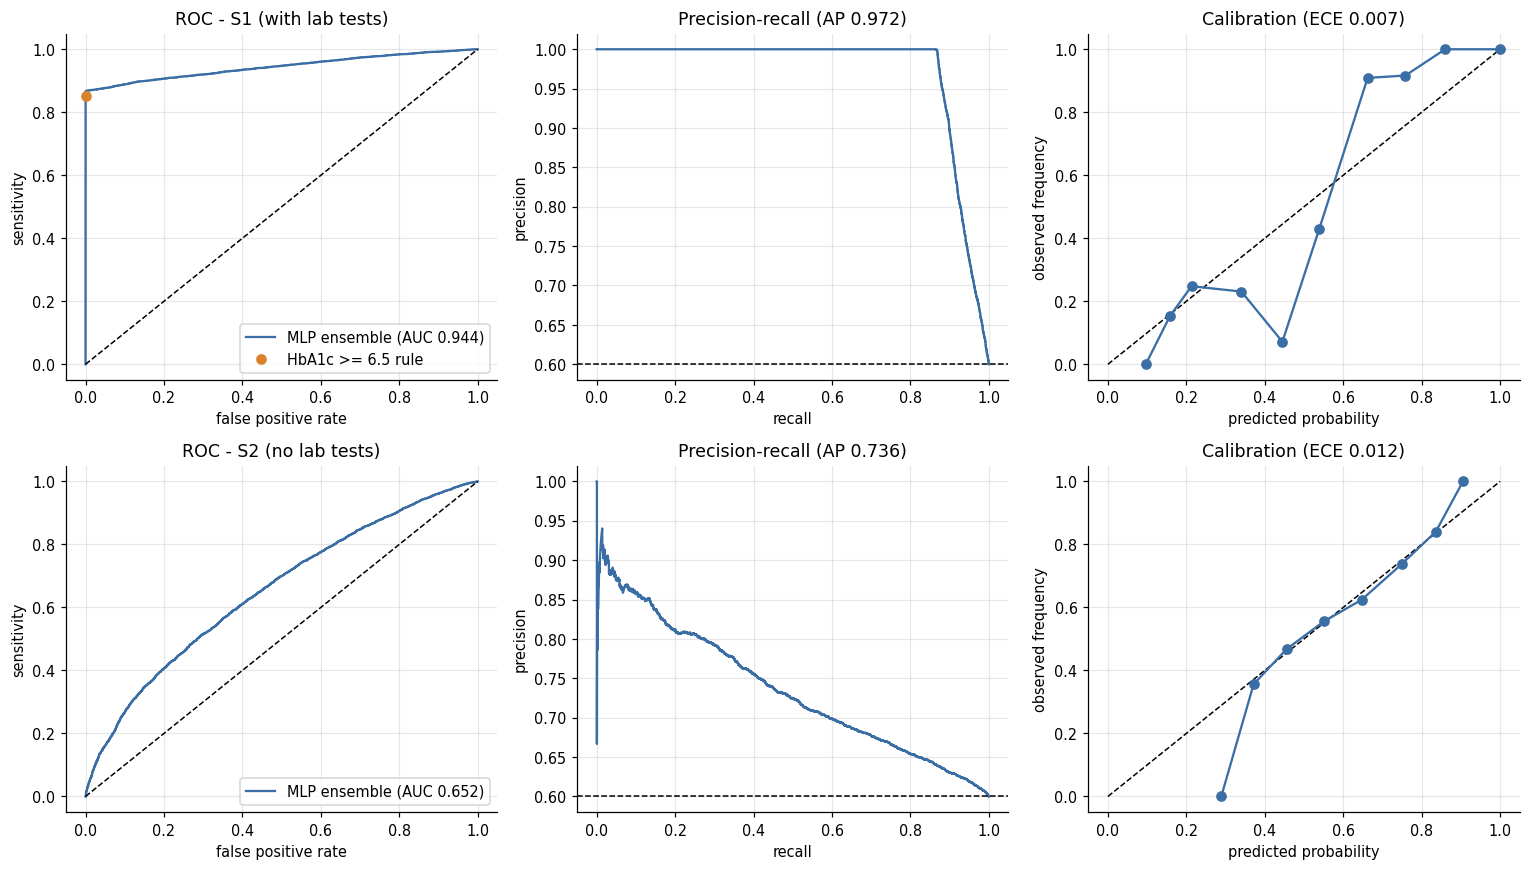

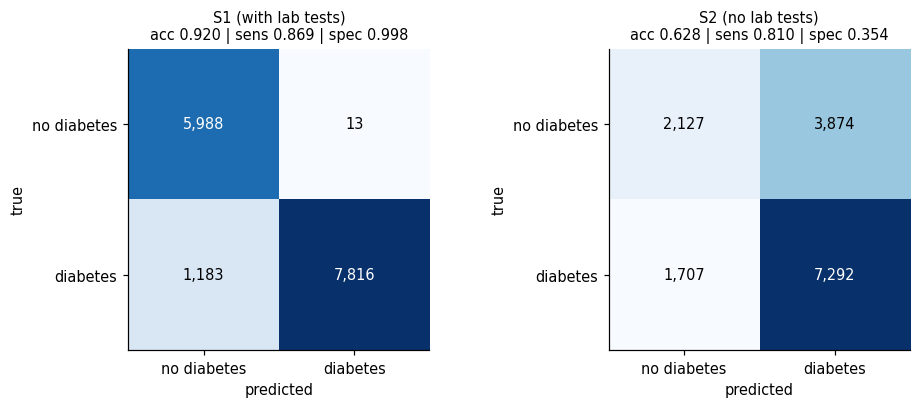

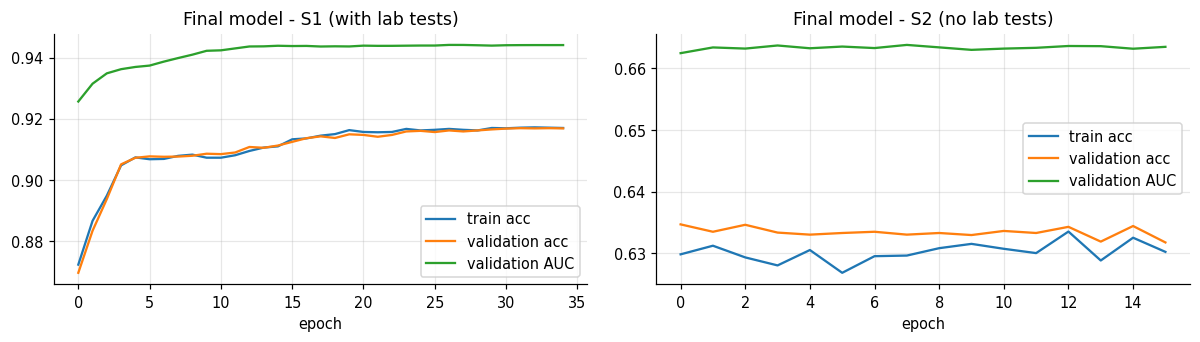

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for j, s in enumerate(SCENS):
    p = FINAL[s]['ens_te']; fpr, tpr, _ = roc_curve(yte_np, p); pr, rc, _ = precision_recall_curve(yte_np, p)
    ax[j, 0].plot(fpr, tpr, color=PAL, label=f"MLP ensemble (AUC {FINAL[s]['m_ens']['auc']:.3f})"); ax[j, 0].plot([0, 1], [0, 1], 'k--', lw=1)
    if s == 'S1': ax[j, 0].plot([1 - RULE['spec']], [RULE['sens']], 'o', color=PAL2, label='HbA1c >= 6.5 rule')
    ax[j, 0].set_xlabel('false positive rate'); ax[j, 0].set_ylabel('sensitivity'); ax[j, 0].set_title(f'ROC - {SNAME[s]}'); ax[j, 0].legend(loc='lower right')
    ax[j, 1].plot(rc, pr, color=PAL); ax[j, 1].axhline(yte_np.mean(), color='k', ls='--', lw=1); ax[j, 1].set_xlabel('recall'); ax[j, 1].set_ylabel('precision'); ax[j, 1].set_title(f"Precision-recall (AP {FINAL[s]['m_ens']['ap']:.3f})")
    bins = np.linspace(0, 1, 11); b = np.minimum((p * 10).astype(int), 9); xs = [p[b == k].mean() for k in range(10) if (b == k).any()]; ys_ = [yte_np[b == k].mean() for k in range(10) if (b == k).any()]
    ax[j, 2].plot([0, 1], [0, 1], 'k--', lw=1); ax[j, 2].plot(xs, ys_, 'o-', color=PAL); ax[j, 2].set_xlabel('predicted probability'); ax[j, 2].set_ylabel('observed frequency'); ax[j, 2].set_title(f"Calibration (ECE {FINAL[s]['m_ens']['ece']:.3f})")
plt.tight_layout(); savefig('final_roc_pr_calibration'); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, s in zip(ax, SCENS):
    m = FINAL[s]['m_ens']; cm = np.array([[m['tn'], m['fp']], [m['fn'], m['tp']]]); a.imshow(cm, cmap='Blues'); a.grid(False)
    a.set_xticks([0, 1]); a.set_xticklabels(['no diabetes', 'diabetes']); a.set_yticks([0, 1]); a.set_yticklabels(['no diabetes', 'diabetes']); a.set_xlabel('predicted'); a.set_ylabel('true'); a.set_title(f"{SNAME[s]}\nacc {m['acc']:.3f} | sens {m['sens']:.3f} | spec {m['spec']:.3f}", fontsize=9.5)
    for i in range(2):
        for k in range(2): a.text(k, i, f'{cm[i, k]:,}', ha='center', va='center', color='white' if cm[i, k] > cm.max() * .55 else 'black')
plt.tight_layout(); savefig('final_confusion'); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, s in zip(ax, SCENS):
    h = FM[s][0]['hist']; a.plot(h['tr_acc'], label='train acc'); a.plot(h['va_acc'], label='validation acc'); a.plot(h['va_auc'], label='validation AUC'); a.set_xlabel('epoch'); a.set_title(f'Final model - {SNAME[s]}'); a.legend()
plt.tight_layout(); savefig('final_curves'); plt.show()

## 17. Interpretation analyses
(a) permutation importance, (b) performance in subgroups, (c) learning curve, (d) threshold trade-off.

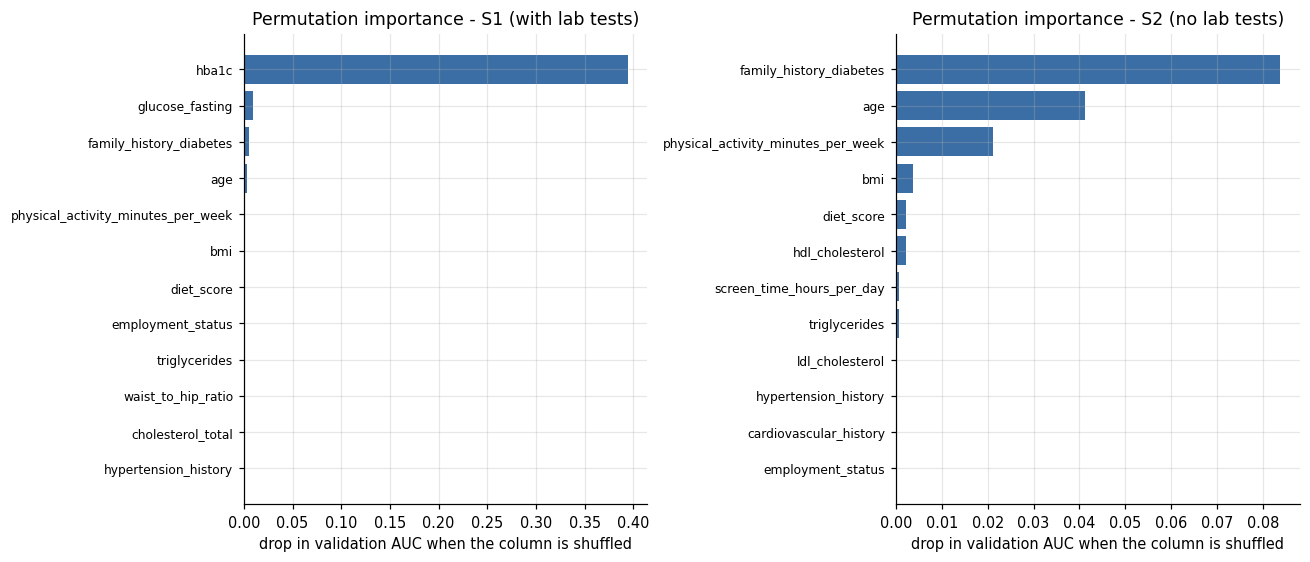

S1 (with lab tests) top-5: [('hba1c', 0.3949), ('glucose_fasting', 0.0096), ('family_history_diabetes', 0.0048), ('age', 0.0029), ('physical_activity_minutes_per_week', 0.0013)]
S2 (no lab tests) top-5: [('family_history_diabetes', 0.0839), ('age', 0.0413), ('physical_activity_minutes_per_week', 0.0211), ('bmi', 0.0037), ('diet_score', 0.0021)]


In [21]:
def ens_predict(s, dframe):
    D = get_data(s, FINAL[s]['P']); X = torch.tensor(D['pre'].transform(dframe), dtype=torch.float32, device=dev)
    with torch.no_grad(): return np.mean([torch.sigmoid(f['model'](X).squeeze(1)).cpu().numpy() for f in FM[s]], 0)
IMP = {}; rng = np.random.RandomState(0); dva = df.iloc[va]
for s in SCENS:
    base_auc = roc_auc_score(yva_np, ens_predict(s, dva)); rows = []
    for c in FEATSETS[s]:
        drops = []
        for _ in range(3):
            dp = dva.copy(); dp[c] = rng.permutation(dp[c].values); drops.append(base_auc - roc_auc_score(yva_np, ens_predict(s, dp)))
        rows.append((c, float(np.mean(drops))))
    IMP[s] = sorted(rows, key=lambda t: -t[1])
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
for a, s in zip(ax, SCENS):
    top = IMP[s][:12][::-1]; a.barh([t[0] for t in top], [t[1] for t in top], color=PAL); a.set_xlabel('drop in validation AUC when the column is shuffled'); a.set_title(f'Permutation importance - {SNAME[s]}'); a.tick_params(axis='y', labelsize=8)
plt.tight_layout(); savefig('final_importance'); plt.show()
for s in SCENS: print(SNAME[s], 'top-5:', [(c, round(v, 4)) for c, v in IMP[s][:5]])

S1 (with lab tests)


,group,n,prevalence,auc,acc,sens,spec
0,gender: Female,7471,0.591,0.943,0.920,0.867,0.997
1,gender: Male,7253,0.608,0.946,0.921,0.870,0.999
2,gender: Other,276,0.627,0.943,0.913,0.861,1.000
3,ethnicity: Asian,1699,0.602,0.940,0.923,0.872,1.000
4,ethnicity: Black,2683,0.612,0.941,0.917,0.865,0.999
5,ethnicity: Hispanic,3103,0.588,0.942,0.920,0.867,0.996
6,ethnicity: Other,717,0.597,0.958,0.923,0.874,0.997
7,ethnicity: White,6798,0.600,0.946,0.921,0.869,0.998
8,age_group: 40-59,7026,0.599,0.948,0.924,0.876,0.997
9,age_group: 60+,4141,0.669,0.948,0.922,0.883,0.999


S2 (no lab tests)


,group,n,prevalence,auc,acc,sens,spec
0,gender: Female,7471,0.591,0.642,0.621,0.812,0.345
1,gender: Male,7253,0.608,0.662,0.634,0.807,0.366
2,gender: Other,276,0.627,0.692,0.663,0.855,0.340
3,ethnicity: Asian,1699,0.602,0.646,0.633,0.822,0.346
4,ethnicity: Black,2683,0.612,0.657,0.634,0.790,0.388
5,ethnicity: Hispanic,3103,0.588,0.642,0.617,0.809,0.345
6,ethnicity: Other,717,0.597,0.651,0.605,0.813,0.298
7,ethnicity: White,6798,0.600,0.657,0.632,0.816,0.354
8,age_group: 40-59,7026,0.599,0.641,0.623,0.844,0.292
9,age_group: 60+,4141,0.669,0.647,0.673,0.973,0.064


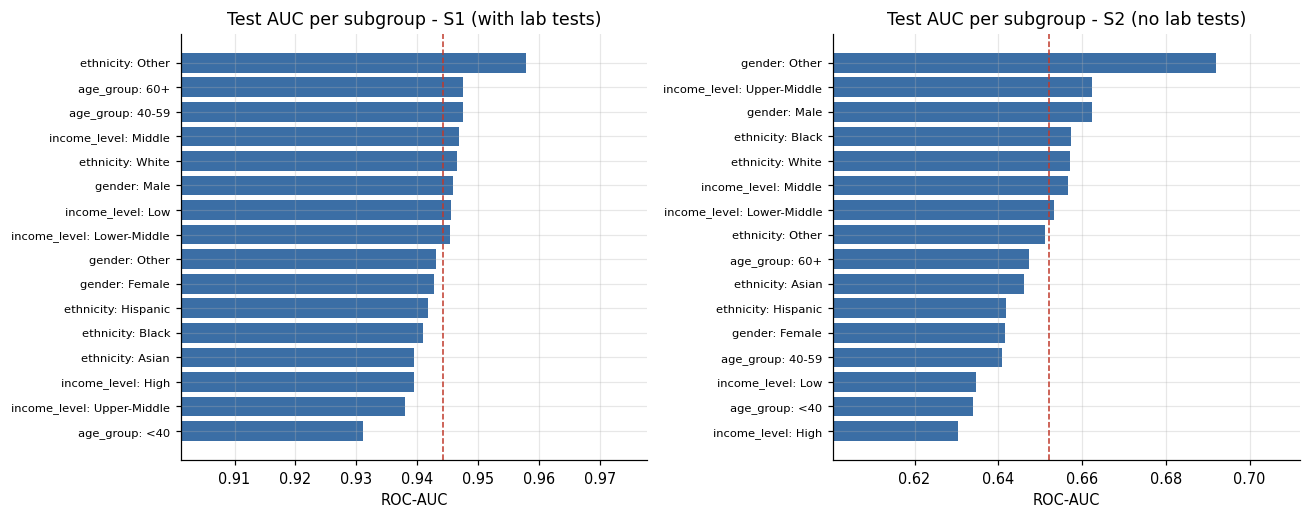

In [22]:
SUB = {}
dte = df.iloc[te].copy(); dte['age_group'] = pd.cut(dte.age, [0, 39, 59, 120], labels=['<40', '40-59', '60+']).astype(str)
for s in SCENS:
    rows = []; p = FINAL[s]['ens_te']
    for col in ('gender', 'ethnicity', 'age_group', 'income_level'):
        for g, idx_g in dte.groupby(col).indices.items():
            yt = yte_np[idx_g]; m = clf_metrics(yt, p[idx_g]) if 0 < yt.sum() < len(yt) else None
            if m: rows.append(dict(group=f'{col}: {g}', n=len(idx_g), prevalence=float(yt.mean()), auc=m['auc'], acc=m['acc'], sens=m['sens'], spec=m['spec']))
    SUB[s] = pd.DataFrame(rows); print(SNAME[s]); display(SUB[s].round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a, s in zip(ax, SCENS):
    d_ = SUB[s].sort_values('auc'); a.barh(d_.group, d_.auc, color=PAL); a.axvline(FINAL[s]['m_ens']['auc'], color='#c0392b', ls='--', lw=1); a.set_xlim(max(.5, d_.auc.min() - .03), d_.auc.max() + .02); a.tick_params(axis='y', labelsize=7.5); a.set_title(f'Test AUC per subgroup - {SNAME[s]}'); a.set_xlabel('ROC-AUC')
plt.tight_layout(); savefig('final_subgroups'); plt.show()

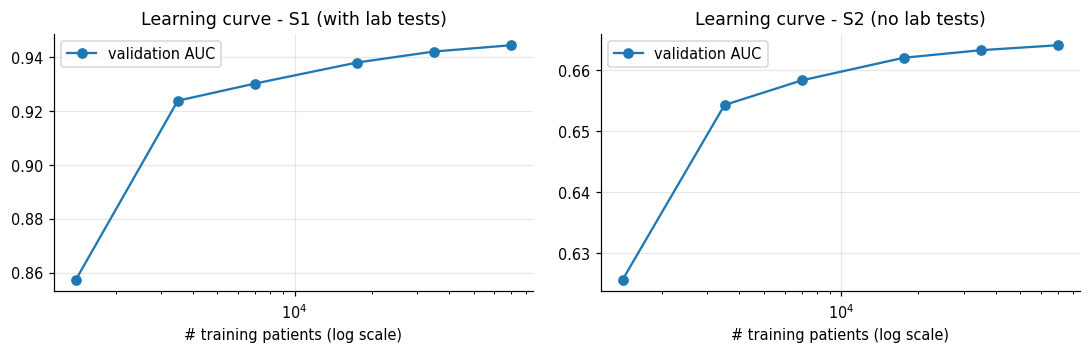

S1 (with lab tests) [(1400, 0.8574), (3500, 0.9239), (7000, 0.9302), (17500, 0.9381), (35000, 0.9422), (70000, 0.9445)]
S2 (no lab tests) [(1400, 0.6256), (3500, 0.6543), (7000, 0.6584), (17500, 0.6621), (35000, 0.6633), (70000, 0.6641)]


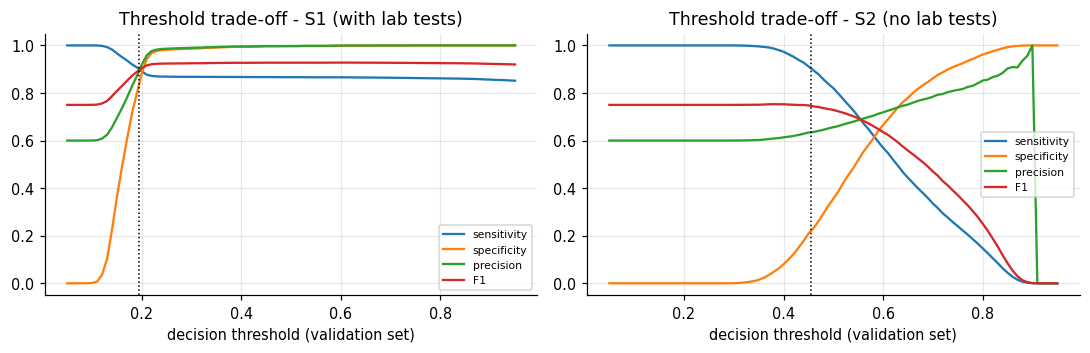

In [23]:
fr = (0.02, 0.05, 0.1, 0.25, 0.5, 1.0); LC = {}
for s in SCENS:
    LC[s] = []
    for f in fr:
        o = [fit(s, FINAL[s]['P'], sd, frac=f, **FINAL[s]['cfg']) for sd in (0, 1)]; LC[s].append((f, float(np.mean([r['va_auc'] for r in o])), float(np.mean([r['tr_acc'] for r in o]))))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for a, s in zip(ax, SCENS):
    a.plot([f * len(tr) for f, _, _ in LC[s]], [v for _, v, _ in LC[s]], 'o-', label='validation AUC'); a.set_xscale('log'); a.set_xlabel('# training patients (log scale)'); a.set_title(f'Learning curve - {SNAME[s]}'); a.legend()
plt.tight_layout(); savefig('learning_curve'); plt.show()
for s in SCENS: print(SNAME[s], [(int(f * len(tr)), round(v, 4)) for f, v, _ in LC[s]])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for a, s in zip(ax, SCENS):
    ths = np.linspace(.05, .95, 91); ms = [clf_metrics(yva_np, FINAL[s]['ens_va'], t) for t in ths]
    for k, nm in (('sens', 'sensitivity'), ('spec', 'specificity'), ('prec', 'precision'), ('f1', 'F1')): a.plot(ths, [m[k] for m in ms], label=nm)
    a.axvline(FINAL[s]['thr_sens'], color='k', ls=':', lw=1); a.set_xlabel('decision threshold (validation set)'); a.set_title(f'Threshold trade-off - {SNAME[s]}'); a.legend(fontsize=7)
plt.tight_layout(); savefig('threshold_tradeoff'); plt.show()

## 18. Summary of all experiments

240 training configurations were evaluated; 432 individual training runs; total training time 42 min
S1 (with lab tests)


,stage,val_auc,val_acc
0,1 baseline,0.9421,0.9077
1,2 + preprocessing,0.9421,0.9079
2,3 + architecture,0.9441,0.9181
3,4 + activation,0.9441,0.9181
4,5 + regularisation,0.9441,0.9181
5,6 + optimisation,0.9441,0.9181
6,7 + loss,0.9441,0.9181
7,"8 final (re-checked, 3 fresh seeds)",0.9445,0.9183


S2 (no lab tests)


,stage,val_auc,val_acc
0,1 baseline,0.6624,0.6332
1,2 + preprocessing,0.6621,0.6330
2,3 + architecture,0.6637,0.6347
3,4 + activation,0.6641,0.6336
4,5 + regularisation,0.6641,0.6336
5,6 + optimisation,0.6641,0.6336
6,7 + loss,0.6641,0.6336
7,"8 final (re-checked, 3 fresh seeds)",0.6640,0.6330


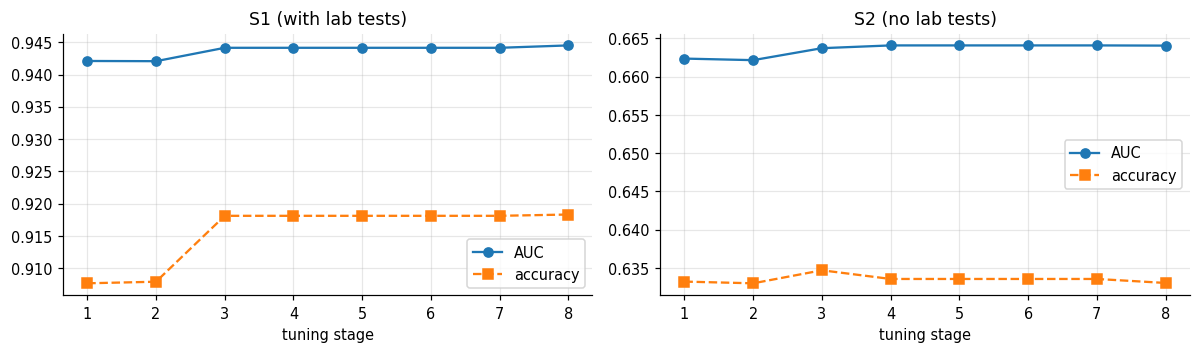

saved results/all_runs.csv, results/final_results.json and figs/*.png


In [24]:
all_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('_hist',)} for r in RUNS])
for c in ('P', 'cfg'): all_df[c] = all_df[c].apply(lambda v: json.dumps(v, default=str))
all_df.to_csv('results/all_runs.csv', index=False)
print(len(all_df), 'training configurations were evaluated;', int(all_df.n_seeds.sum()), 'individual training runs; total training time %.0f min' % ((all_df['time'] * all_df['n_seeds']).sum() / 60))
PROG = {}
for s in SCENS:
    st = [('1 baseline', base[s]), ('2 + preprocessing', SW_PREP[s]['comb'] if SW_PREP[s]['comb']['va_auc'] >= SW_PREP[s]['base']['va_auc'] else SW_PREP[s]['base']),
          ('3 + architecture', best_mlp(s)), ('4 + activation', max(ACTR[s], key=lambda r: r['va_auc'])),
          ('5 + regularisation', SW_REG[s]['comb']), ('6 + optimisation', SW_OPT[s]['comb']), ('7 + loss', SW_LOSS[s]['comb']), ('8 final (re-checked, 3 fresh seeds)', FINAL[s]['rec'])]
    PROG[s] = pd.DataFrame([dict(stage=n, val_auc=r['va_auc'], val_acc=r['va_acc']) for n, r in st]); print(SNAME[s]); display(PROG[s].round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for a, s in zip(ax, SCENS):
    a.plot(range(len(PROG[s])), PROG[s].val_auc, 'o-', label='AUC'); a.plot(range(len(PROG[s])), PROG[s].val_acc, 's--', label='accuracy'); a.set_xticks(range(len(PROG[s]))); a.set_xticklabels([t.split(' ')[0] for t in PROG[s].stage]); a.set_xlabel('tuning stage'); a.set_title(SNAME[s]); a.legend()
plt.tight_layout(); savefig('progress'); plt.show()
def fin_json(s):
    F_ = FINAL[s]; sg = lambda k: [m[k] for m in F_['single']]
    return dict(P=F_['P'], cfg={k: (list(v) if isinstance(v, tuple) else v) for k, v in F_['cfg'].items()}, n_params=int(FM[s][0]['n_params']), single_acc=sg('acc'), single_auc=sg('auc'), single_f1=sg('f1'),
                ens=F_['m_ens'], ci_acc=F_['ci_acc'], ci_auc=F_['ci_auc'], ens_f1thr=F_['m_f1'], ens_sensthr=F_['m_sens'], thr_f1=F_['thr_f1'], thr_sens=F_['thr_sens'], val_auc=float(np.mean([f['va_auc'] for f in FM[s]])), val_acc=float(np.mean([f['va_acc'] for f in FM[s]])),
                importance=IMP[s], subgroups=SUB[s].to_dict('records'), learning_curve=LC[s], progress=PROG[s].to_dict('records'), baseline=dict(auc=base[s]['va_auc'], acc=base[s]['va_acc'], f1=base[s]['va_f1']),
                adopted=dict(prep=SW_PREP[s]['adopt'], reg=SW_REG[s]['adopt'], opt=SW_OPT[s]['adopt'], loss=SW_LOSS[s]['adopt']), linear_auc=ARCH[s]['linear']['va_auc'], linear_acc=ARCH[s]['linear']['va_acc'])
json.dump(dict(student='Adel Ahmed Fathi Amer', student_id='224100177', data=CLEAN, split=dict(train=len(tr), val=len(va), test=len(te)), majority_acc=MAJ, rule_hba1c=RULE, sklearn=SK,
               featsets=[{k: r[k] for k in ('label', 'va_auc', 'va_acc', 'va_f1')} | {'n_inputs': len(FEATSETS[r['label']])} for r in fsets], S1=fin_json('S1'), S2=fin_json('S2')),
          open('results/final_results.json', 'w'), indent=1, default=str)
print('saved results/all_runs.csv, results/final_results.json and figs/*.png')

## 19. Conclusions
* **S1 (with lab tests):** an ensemble of five tiny MLPs (4 x 16, 1,585 parameters each) reaches **92.0 % test accuracy (95 % CI 91.6-92.5), AUC 0.944, F1 0.929, sensitivity 0.869, specificity 0.998**; single models 91.9 % +- 0.1. This beats the majority class (60.0 %) by 32 points and the clinical rule *HbA1c >= 6.5* (accuracy 91.0 %, sensitivity 0.851, specificity 1.000) by about one point: the network essentially **rediscovers the HbA1c threshold rule** (shuffling HbA1c lowers AUC by 0.39, the next feature - fasting glucose - by only 0.01) and adds a little from glucose and risk factors. No amount of tuning, capacity or preprocessing moved AUC beyond ~0.944; the roughly 13-15 % of diagnosed patients that fall below the HbA1c threshold (13.1 % missed by the ensemble, 14.9 % by the rule) could not be identified from the available columns (this suggests, but does not prove, that part of the label in this synthetic dataset is not explained by the recorded measurements).
* **S2 (no lab tests):** **62.8 % accuracy (95 % CI 62.0-63.5), AUC 0.652 (95 % CI 0.643-0.660)**. This is significantly better than always predicting the majority class (60.0 %) but weak: at threshold 0.5 sensitivity is 0.81 and specificity 0.35. The informative columns are family history, age and physical activity (importance 0.084 / 0.041 / 0.021 AUC). Such a model can rank patients for screening priority, not diagnose them.
* **Probabilities are well calibrated** in both scenarios (ECE 0.007 / 0.012; Brier 0.066 and 0.2235 vs 0.24 for a constant prediction), so they can be read as risk estimates; thresholds can be moved to the clinical need (S1: sensitivity 0.90 at threshold 0.20 costs specificity 0.836).
* **Subgroups:** S1 AUC is 0.931-0.958 across gender, ethnicity, age and income groups (lowest for patients under 40, where sensitivity is 0.83); S2 AUC is 0.630-0.692. No group is badly served, but some groups are small.
* **Data caveats:** the data are **synthetic**, so conclusions about real patients are not justified; the Kaggle description (35+ columns, 20-25 % positives) does not match the file (31 columns, 60 % positives); `diabetes_stage` leaks the label and must never be used as an input; and the models are close to data-saturated (the learning curve gains only +0.002 AUC from 35k to 70k training patients in S1, and +0.002 from 17.5k to 70k in S2).